# Sections I–III: Business Needs, Data Exploration, Preprocessing and Simple Classification Model

This notebook covers Sections I and II and Section III up to a first complete model and Kaggle submission:

1. **Identifying Business Needs**
2. **Data Exploration and Preprocessing**
3. **Binary Classification & Optimization: first complete model and Kaggle submission**

The first section defines the prediction problem, project objective, overall workflow and model-assessment strategy. The second section examines the supplied data, records the main findings and applies the initial cleaning decisions required before modelling.

## Contents <a class="anchor" id="toc"></a>

**I. Identifying Business Needs**

- [1.1 Business problem and project objective](#business-problem)
- [1.2 Overall project process](#overall-process)
- [1.3 Model-assessment approach](#assessment)

**II. Data Exploration and Preprocessing**

- [Overview of the data exploration](#exploration)
- [2.1 Setup and data import](#s1-1)
- [2.2 First look at the data](#s1-2)
- [2.3 The target variable](#s1-3)
- [2.4 Train vs. test: what will we be predicting?](#s1-4)
- [2.5 Data quality and inconsistencies](#s1-5)
- [2.6 Univariate exploration: one variable at a time](#s1-6)
- [2.7 Relationship with the target](#s1-7)
- [2.8 Correlations between variables](#s1-8)
- [2.9 The customer table (`clientes.csv`)](#s1-9)
- [2.10 Exploration summary: findings and preprocessing decisions](#eda-summary)
- [2.11 Initial preprocessing](#preprocessing)
  - [2.11.1 Setup and reload raw data](#s2-1)
  - [2.11.2 Cleaning rules carried forward from the exploration](#s2-2)
  - [2.11.3 Remove rows with no predictor information](#s2-3)
  - [2.11.4 Correct impossible numeric values](#s2-4)
  - [2.11.5 Preserve first-purchase information](#s2-5)
  - [2.11.6 Dates and identifiers](#s2-6)
  - [2.11.7 Optional customer table](#s2-7)
  - [2.11.8 Additional checks from the exploration](#s2-8)
  - [2.11.9 Reusable preprocessing pipeline for modelling](#s2-9)
  - [2.11.10 Final checks and saved outputs](#s2-10)
- [2.12 Section II summary](#summary)

**III. Binary Classification & Optimization**

- [3.1 Objective of this section](#s3-1)
- [3.2 Assessment strategy and metric](#s3-2)
- [3.3 Baseline: logistic regression](#s3-3)
- [3.4 Testing preprocessing choices](#s3-4)
- [3.5 Feature selection](#s3-5)
- [3.6 Final model and Kaggle submission](#s3-6)
- [3.7 Conclusion](#s3-7)

# I. Identifying Business Needs

## 1.1 Business problem and project objective <a class="anchor" id="business-problem"></a>

The project addresses a **binary classification problem**. For each purchase occasion, the objective is to predict whether the customer will make another purchase within the following 90 days.

The target variable is `repeat_purchase_90d`:

- `1` - the customer purchases again within 90 days;
- `0` - the customer does not purchase again within 90 days.

From a business perspective, the prediction can help distinguish purchase occasions associated with a higher or lower probability of near-term customer return. This can support customer-retention analysis and the prioritisation of commercial actions.

The modelling objective is therefore to use the information available at the time of each purchase to estimate the probability of a repeat purchase within 90 days. The final solution must also generalise to the later observations supplied in the test set.

## 1.2 Overall project process <a class="anchor" id="overall-process"></a>

The work is organised as a sequence of connected stages:

1. **Understand the data** - inspect the supplied files, variables, target and time coverage.
2. **Explore data quality** - identify missing values, invalid values, duplicates, unusual observations and internal inconsistencies.
3. **Explore potentially useful information** - examine numerical and categorical variables, temporal behaviour and relationships with the target.
4. **Apply initial preprocessing** - correct data-quality problems and create the basic variables required for modelling.
5. **Assess candidate models** - compare classification algorithms using a validation procedure that reflects the prediction setting.
6. **Feature selection and optimisation** - evaluate redundant or weak variables and tune the strongest candidate models.
7. **Final training and prediction** - refit the selected solution using the available training data and generate predictions for the test set.

Exploration and preprocessing are kept separate where useful: the exploration first establishes *why* a transformation is necessary, and the preprocessing section then applies that decision.

## 1.3 Model-assessment approach <a class="anchor" id="assessment"></a>

The project uses a **time-based cross-validation** (`TimeSeriesSplit`, 5 folds) as the model-assessment approach.

The data has a clear time order: all the test purchases (May 2025 - October 2026) happen after the training purchases (July 2015 - February 2025), as shown in 2.4. A random split would mix earlier and later purchases, so it would not imitate the real task, where we predict the future from the past. Also, the same customer appears in many purchases (6,534 purchases from only 610 customers, see 2.2), which makes a simple random split of the rows less appropriate.

The training data is sorted by date. Each fold trains on the earlier purchases and validates on the period that follows:

**earlier purchases → model training → later purchases → validation**

Each of these train/validation splits is called a *fold*. Repeating this 5 times gives an average score and shows how much it varies between periods, which a single split cannot do. Everything the model learns from the data (the medians used to fill gaps, the scaling, which columns to keep) is learned only from the training part of each fold, never from the part used to test it. The metric is **F1**, the metric of the Kaggle competition (details in 3.2).

Once the final model is chosen, it is trained again on all the training data and then used to predict the test set.

# II. Data Exploration and Preprocessing

## Overview of the data exploration <a class="anchor" id="exploration"></a>

**Purpose:** describe the supplied data, identify the main data-quality issues and extract findings that affect preprocessing or later modelling decisions.

This section does not modify the source data. Problems are first documented so that each cleaning step can be linked to an observed issue. The corresponding transformations are applied in Section 2.11.

### Exploration contents
- Setup and data import
- First look at the data
- Target variable
- Train versus test
- Data quality and inconsistencies
- Univariate exploration
- Relationship with the target
- Correlations between variables
- The customer table (`clientes.csv`)
- Exploration summary

## <font color='#E8800A'>2.1 Setup and data import</font> <a class="anchor" id="s1-1"></a>


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency          # chi-square test (used in 2.5.3 and 2.7.2)
from scipy.stats.contingency import association  # Cramér's V (used in 2.5.3 and 2.7.2)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

#data folder location: root of the project, as is the notebooks folder.
DATA_DIR = Path("../data")   
TARGET = "repeat_purchase_90d"

In [2]:
# read the amount of data in each file of the "data" folder
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
clientes = pd.read_csv(DATA_DIR / "clientes.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

for name, df in [("train", train), ("test", test), ("clientes", clientes), ("sample_submission", sample_submission)]:
    print(f"{name:<18} {df.shape[0]:>6} rows x {df.shape[1]:>3} columns")

train                6534 rows x  39 columns
test                  986 rows x  38 columns
clientes             1143 rows x  13 columns
sample_submission     986 rows x   2 columns


In [3]:
# Check: does clientes.csv have exactly one row per customer?
print("Rows in clientes:", len(clientes), "| distinct customer_id:", clientes["customer_id"].nunique())
print("Every train customer is in clientes:", train["customer_id"].isin(clientes["customer_id"]).all())

Rows in clientes: 1143 | distinct customer_id: 1143
Every train customer is in clientes: True


- **Each row of `train`/`test` is one purchase** (an invoice event) of a customer. The target says whether that customer bought again in the following 90 days (we will talk about this later).
- `clientes.csv` has **one row per customer** (customer master data) and can be joined through `customer_id`.
- `sample_submission.csv` shows the format to submit: `ID` + predicted `repeat_purchase_90d`.

## <font color='#E8800A'>2.2 First look at the data</font> <a class="anchor" id="s1-2"></a>


In [4]:
#head shows the first 5 rows of the dataframe
train.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


In [5]:
def overview(df):
    """One row per column: type, missing values and number of distinct values."""
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(1),
        "n_unique": df.nunique(),
        "example": df.iloc[0],
    })

overview(train)

,dtype,n_missing,pct_missing,n_unique,example
Total a Pagar,float64,65,1.0,6122,558.11
Total Bruto,float64,65,1.0,6038,510.9
Total Liquido,float64,65,1.0,6093,453.75
Total Imp_,float64,65,1.0,5406,104.36
Total Portes,float64,65,1.0,215,0.0
Total Desc_ Global,float64,65,1.0,109,0.0
Total Desc_ Linha,float64,65,1.0,3519,57.15
Custo,float64,65,1.0,5736,153.099911
N_ Detalhes,float64,65,1.0,171,4.0
invoice_count_current_purchase,float64,65,1.0,5,1.0


In [6]:
# How many purchases does each customer have?
purchases_per_customer = train["customer_id"].value_counts()   # counts the rows of each customer_id
display(purchases_per_customer.describe().round(1))             

print("Customers with the most purchases:")
display(purchases_per_customer.head(5))

print("Customers with a single purchase:", (purchases_per_customer == 1).sum())
top10 = purchases_per_customer.head(int(len(purchases_per_customer) * 0.10))
print(f"Share of all rows coming from the top 10% customers: {top10.sum() / len(train):.0%}")

count    610.0
mean      10.7
std       20.0
min        1.0
25%        1.0
50%        4.0
75%       12.0
max      277.0
Name: count, dtype: float64

Customers with the most purchases:


customer_id
103940    277
258332    203
755628    112
519184     89
151492     89
Name: count, dtype: int64

Customers with a single purchase: 157
Share of all rows coming from the top 10% customers: 50%


**What the overview above tells us**

- **Observations:** each row is **one purchase**, not one customer, which means that the 6,534 purchases come from only 610 customers. The number of purchases per customer is very uneven: the average is ~11 but the median is only 4, 157 customers appear only once and one customer has 277 purchases.
The top 10 % of customers account for half of all rows. Rows of the same customer are related to each other, which we must keep in mind when splitting the data for validation:
if the same customer appears both in the data used to train the model and in the data used to test it, the model may simply "recognise" that customer instead of learning general patterns.
- **Missing values:** almost every column has exactly 65 missing values: probably rows that are
  completely empty, though some columns have many more missing values (up to ~23 %).

### Columns - what are they for?

Summary of the 39 columns by **what they describe**:

| Group | Columns | Meaning |
|---|---|---|
| Current purchase (invoice) | `Total a Pagar`, `Total Bruto`, `Total Liquido`, `Total Imp_`, `Total Portes`, `Total Desc_ Global`, `Total Desc_ Linha`, `Custo`, `N_ Detalhes`, `invoice_count_current_purchase` | Amounts, taxes, shipping, discounts, cost and number of lines of the purchase |
| Customer history | `days_since_previous_purchase`, `customer_tenure_days`, `prior_purchase_count`, `prior_total_spend`, `prior_*_purchase_value`, `prior_*_gap_days` | What the customer did **before** this purchase (recency, tenure, frequency, monetary value, regularity) |
| Recent activity windows | `purchase_count_{30,90,180,365}d`, `spend_{30,90,180,365}d` | Number of purchases and spend in the last 30/90/180/365 days |
| Context (categorical) | `payment_type`, `salesperson`, `commercial_zone`, `transport_method`, `warehouse`, `document_series` | How/where the sale was made |
| Date | `purchase_date` | Date of the purchase (stored as text) |
| Identifiers | `ID`, `customer_id` | Row id (needed for submission) and customer key (needed to join `clientes`) |
| Suspicious | `random_noise` | As the name says, probably noise |
| **Target** | `repeat_purchase_90d` | 1 = the customer bought again within 90 days |

## <font color='#E8800A'>2.3 The target variable</font> <a class="anchor" id="s1-3"></a>


### What is the target and what do we want to do here?

**The target** is `repeat_purchase_90d`, the variable the model has to predict:

| Value | Meaning |
|---|---|
| `1` | after this purchase, the customer **bought again within the next 90 days** (repeat purchase) |
| `0` | the customer did **not** buy again in those 90 days |

Each row is one purchase, so the question the model answers is:
*"Given what we know at the moment of this purchase (the invoice, the customer's history and recent activity), will this customer come back within 90 days?"*

**Why this matters for the business:** a company that knows in advance which customers are unlikely to come back
can act on them (reminders, promotions, follow-up calls) before they are lost.

,count,proportion
repeat_purchase_90d,,
1,3654,0.56
0,2880,0.44


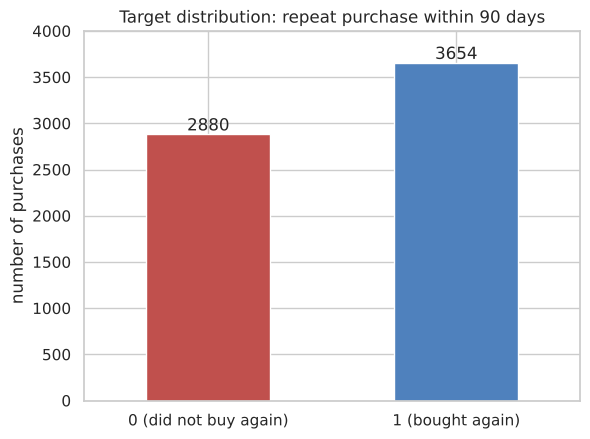

Majority-class baseline accuracy: 56.0%


In [7]:
# Count how many purchases fall in each class of the target (0 = no repeat, 1 = repeat)
target_dist = train[TARGET].value_counts().to_frame("count")

# Convert the counts into proportions (share of all purchases)
target_dist["proportion"] = (target_dist["count"] / len(train)).round(2)
display(target_dist)

# Bar chart of the two classes; sort_index() puts class 0 first and class 1 second
counts = train[TARGET].value_counts().sort_index()
ax = counts.plot.bar(color=["#c0504d", "#4f81bd"], rot=0)
ax.set_xticks([0, 1], labels=["0 (did not buy again)", "1 (bought again)"])
ax.bar_label(ax.containers[0])                                               
ax.set(title="Target distribution: repeat purchase within 90 days", xlabel="", ylabel="number of purchases", ylim=(0, 4000))
plt.show()

# Baseline accuracy: if we always predict the majority class, what accuracy would we get?
baseline_acc = target_dist["proportion"].max()
print(f"Majority-class baseline accuracy: {baseline_acc:.1%}")

**Insight:** about 56 % of purchases are followed by another purchase within 90 days and 44 % are not.
This means that our target is close to balanced, so we do not need any special
technique to make them equal.
A trivial model that always predicts 1 already gets ~56 % accuracy (our *baseline* to beat).

## <font color='#E8800A'>2.4 Train vs. test: what will we be predicting?</font> <a class="anchor" id="s1-4"></a>


In [8]:
print("Columns only in train:", set(train.columns) - set(test.columns))

#as we will see below, there is no column that is in test but not in train, 
# so we don't need to worry about that.
print("Columns only in test :", set(test.columns) - set(train.columns))

dates = pd.DataFrame({
    "train": pd.to_datetime(train["purchase_date"]).agg(["min", "max"]),
    "test": pd.to_datetime(test["purchase_date"]).agg(["min", "max"]),
})
display(dates)

overlap = test["customer_id"].isin(train["customer_id"]).mean()
print(f"Test rows whose customer also appears in train: {overlap:.1%}")
print(f"Distinct customers - train: {train['customer_id'].nunique()}, test: {test['customer_id'].nunique()}")

Columns only in train: {'repeat_purchase_90d'}
Columns only in test : set()


,train,test
min,2015-07-11,2025-05-24
max,2025-02-15,2026-10-06


Test rows whose customer also appears in train: 94.5%
Distinct customers - train: 610, test: 206


**Insights**
- The test set has the same columns minus the target, as expected.
- **Test purchases are all later than the training purchases** (train ends in Feb 2025, test starts in May 2025).
- Most test customers already appear in train, so their purchase history is available for most test purchases.

## <font color='#E8800A'>2.5 Data quality and inconsistencies</font> <a class="anchor" id="s1-5"></a>


We check, in order: descriptive statistics, empty rows, missing values, impossible values,
consistency and duplicates.

In [9]:
# Column groups used from here on (derived from the data types)
ID_COLS = ["ID", "customer_id"]                                                          # identifiers, not features
NUM_COLS = train.select_dtypes("number").columns.drop(ID_COLS + [TARGET]).tolist()       # numeric variables
CAT_COLS = train.select_dtypes(exclude="number").columns.drop("purchase_date").tolist()  # text categories

### 2.5.1 Descriptive statistics

In [10]:
# descriptive statistics of the numeric variables (one row per variable)
train[NUM_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,925.56,1335.00,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,6469.0,886.15,1327.64,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,6469.0,773.34,1136.36,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,6469.0,152.22,225.26,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,6469.0,1.15,5.84,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,6469.0,0.35,5.12,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,6469.0,112.47,289.99,0.00,0.00,13.13,92.28,4.103440e+03
Custo,6469.0,328.17,519.51,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,6469.0,21.52,27.71,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,6469.0,1.07,0.31,1.00,1.00,1.00,1.00,5.000000e+00


Looking at the table above, some values clearly do not make sense:

- **Fake "one billion" values.** In `prior_mean_purchase_value` and `spend_365d` the largest value is
  1,000,000,000. Unless they are Elon Musk or Mark Zuckerberg, no one in the shop would spend a billion. So these are probably "filler" numbers that were put in the system when the real value was unknown. Because a few of these giant numbers exist, the **average** of these columns is way higher than it should be, up to millions, while the **typical** customer is in the hundreds or thousands.
- **Negative days and negative money.** Some rows say the previous purchase was "−4 days ago", or that
  the customer spent a negative amount. That is impossible, so these are wrong.
- **A few very big purchases.** In the money columns, most purchases are small, but a handful are very
  large. This makes the average much higher than the median value. We need to keep this in mind.
- **`random_noise` looks like computer-generated random numbers.** Its average is about 0, its standard deviations about 1 and its values go from about −3.5 to 4, and this, together with its name, suggests it has nothing to do with the customers. We will check later whether it is related to the target at all.

### 2.5.2 Completely empty rows

In [11]:
# all columns except the identifiers and the target
feature_cols = train.columns.drop(ID_COLS + [TARGET])
empty_rows = train[feature_cols].isna().all(axis=1)
print(f"Rows with ALL features missing: {empty_rows.sum()}  (target mean in them: {train.loc[empty_rows, TARGET].mean():.2f})")
print(f"Empty rows in test: {test[feature_cols].isna().all(axis=1).sum()}")

Rows with ALL features missing: 65  (target mean in them: 0.51)
Empty rows in test: 0


**65 training rows contain only `ID`, `customer_id` and the target**, so no information to learn from.
They do not occur in testing, which means they should be **dropped** in preprocessing.

### 2.5.3 Missing values (excluding the empty rows)

Now we look at the gaps that remain once we ignore the 65 empty rows: which columns have missing values,
and how many? We do the same for test, to see whether the problem looks similar there.

In [12]:
# keep only the rows that are not completely empty
non_empty = train[~empty_rows]

# count the missing values of each column (number and %), in train and in test
missing = pd.DataFrame({
    "train_missing": non_empty.isna().sum(),
    "train_%": (non_empty.isna().mean() * 100).round(1),
    "test_missing": test.isna().sum(),
    "test_%": (test.isna().mean() * 100).round(1),
})

# show only the columns with at least one missing value, from the most to the least affected
missing[missing[["train_missing", "test_missing"]].sum(axis=1) > 0].sort_values("train_%", ascending=False)

,train_missing,train_%,test_missing,test_%
prior_std_gap_days,1413,21.8,69.0,7.0
prior_mean_gap_days,1243,19.2,76.0,7.7
prior_std_purchase_value,1048,16.2,46.0,4.7
days_since_previous_purchase,796,12.3,52.0,5.3
prior_mean_purchase_value,797,12.3,52.0,5.3
prior_max_purchase_value,603,9.3,22.0,2.2
prior_min_purchase_value,603,9.3,22.0,2.2
payment_type,195,3.0,30.0,3.0
salesperson,194,3.0,30.0,3.0
spend_365d,195,3.0,30.0,3.0


The same question can be asked **by row** instead of by column: how many purchases have at least one missing value?

In [13]:
# number of rows with at least one missing value, and number of columns with at least one missing value
rows_with_null = non_empty.isna().any(axis=1)
pd.Series({
    "rows with at least one missing value": f"{rows_with_null.sum():,} of {len(non_empty):,} ({rows_with_null.mean():.1%})",
    "columns with at least one missing value": f"{(non_empty.isna().sum() > 0).sum()} of {non_empty.shape[1]}",
}).to_frame("missing values (non-empty rows)")

,missing values (non-empty rows)
rows with at least one missing value,"2,540 of 6,469 (39.3%)"
columns with at least one missing value,12 of 39


Looking at the missing values above, we can conclude that deleting every incomplete row would throw away about 39% of the data, and deleting every column with a gap would remove 12 columns, including some of the history variables. Neither is a good option, so the gaps will have to be **filled in** (preprocessing, 2.11).

Most of the gaps are in the **history** columns. Maybe these purchases are the customer's
**first purchase**, so there is simply no history to report yet. The next cell checks this by comparing
first purchases with all the others.

In [14]:
# history columns: what the customer did before this purchase
history_cols = ["days_since_previous_purchase", "customer_tenure_days"] + \
               [c for c in train.columns if c.startswith("prior_")]

# a purchase is a "first purchase" when the customer had no purchases before it
first_purchase = non_empty["prior_purchase_count"] == 0
print(f"First purchases (no previous purchases): {first_purchase.sum()}")

# share of missing values in each history column, for first purchases vs. the others
print("\n\nShare of missing values, first purchases vs. the rest:")
display(non_empty.groupby(first_purchase)[history_cols].apply(lambda g: g.isna().mean().round(2)).T
        .rename(columns={False: "has prior purchases", True: "first purchase"}))

First purchases (no previous purchases): 603


Share of missing values, first purchases vs. the rest:


prior_purchase_count,has prior purchases,first purchase
days_since_previous_purchase,0.03,1.0
customer_tenure_days,0.00,0.0
prior_purchase_count,0.00,0.0
prior_total_spend,0.00,0.0
prior_mean_purchase_value,0.03,1.0
prior_std_purchase_value,0.08,1.0
prior_min_purchase_value,0.00,1.0
prior_max_purchase_value,0.00,1.0
prior_mean_gap_days,0.11,1.0
prior_std_gap_days,0.14,1.0


**What we learn:**
- For a customer's **first purchase**, the 7 history columns that describe previous purchases (days since the previous purchase, prior purchase values and gaps) are always empty, and that makes sense: you cannot compute "days since the previous purchase" if there was no previous purchase. These gaps are not errors, they are *expected*. (`customer_tenure_days`, `prior_purchase_count` and `prior_total_spend` are never empty: for a first purchase they are simply 0.)
- Some columns need even more history: to measure the typical time *between* purchases (`prior_mean_gap_days`), a customer needs at least two earlier purchases. That is why these columns have the most gaps.
- The rest (about 3 % of rows in `spend_365d` and in 4 of the 6 categorical columns) are values that were simply not recorded.

Since the two kinds of gaps have different causes, we need to treat them differently in initial preprocessing (for example, adding a column that says "this is a first purchase" before filling in the gaps).

#### Why are the values missing? (MCAR, MAR, MNAR)

Before filling a gap, it helps to know **why** it is empty. There are three possibilities:

- **MCAR** (missing completely at random) → the value is missing by pure chance. Example: a system error lost it.
- **MAR** (missing at random) → the gap can be explained by **another column we can see**.
  Example: the history is empty *because* the customer had no previous purchase (`prior_purchase_count` = 0).
- **MNAR** (missing not at random) → the gap is related to **the missing value itself**, so we cannot see the reason.
  Example: customers who spend a lot prefer not to say how much they spend.

The history gaps are **MAR** , as we showed above, so what about the other gaps (in `spend_365d` and 4 categorical columns)? A simple check: if they happen by pure chance, they should be spread **evenly** across the categories (e.g. every salesperson should have about the same % of gaps).
If they pile up in one category, something is causing them.

To measure this we use:
- **Cramér's V** – how strongly the gaps are linked to a category: **0 = not linked at all, 1 = completely linked**;
- **p-value** – below 0.05 means the link is unlikely to be chance;
- **min expected count** – if it is below 5, there is too little data in some category and the test cannot be trusted.

In [15]:
# mark the rows with a gap OUTSIDE the history columns (the gaps that are NOT explained by a first purchase)
other_cols = non_empty.columns.drop(history_cols + ID_COLS + [TARGET])
gap_flag = non_empty[other_cols].isna().any(axis=1)
print(f"Rows with a gap outside the history columns: {gap_flag.sum()} ({gap_flag.mean():.1%})")
print(f"Missing cells in those columns: {non_empty[other_cols].isna().sum().sum()} "
      f"(if they were in the same rows, there would be far fewer rows than cells)")

# for each categorical variable: are these gaps linked to some categories?
rows = []
for col in CAT_COLS:
    table = pd.crosstab(gap_flag, non_empty[col])            # count of rows with / without a gap, per category
    chi2, p, _, expected = chi2_contingency(table)           # chi-square test on that table
    rows.append({"variable": col,
                 "Cramer's V": round(association(table, method="cramer", correction=True), 3),
                 "p-value": round(p, 3),
                 "min expected count": round(expected.min(), 2)})
display(pd.DataFrame(rows).set_index("variable"))

# are the gaps spread evenly over the years?
year = pd.to_datetime(non_empty["purchase_date"]).dt.year
print("% of rows with a gap, per year:", (gap_flag.groupby(year).mean() * 100).round(1).to_dict())

Rows with a gap outside the history columns: 925 (14.3%)


Missing cells in those columns: 975 (if they were in the same rows, there would be far fewer rows than cells)


,Cramer's V,p-value,min expected count
variable,,,
payment_type,0.027,0.793,0.47
salesperson,0.015,0.993,0.35
commercial_zone,0.035,0.096,0.14
transport_method,0.114,0.392,0.12
warehouse,0.000,1.000,2.44
document_series,0.021,0.226,261.39


% of rows with a gap, per year: {2015: 15.5, 2016: 15.5, 2017: 12.5, 2018: 13.8, 2019: 18.6, 2020: 15.2, 2021: 12.7, 2022: 13.5, 2023: 15.0, 2024: 11.6, 2025: 20.5}


**What we learn:**
- About 14 % of the purchases (925) have one of these gaps. There are 975 missing cells in 925 rows, so almost every gap is in a **different row** (the gaps are scattered, not concentrated in a few broken rows).
- Cramér's V is close to 0 for every variable (at most 0.11) and no p-value is below 0.05: the gaps are **not linked to any category**.
  They also appear at a similar rate every year.
- Careful: for most variables the "min expected count" is below 5, so those tests are not fully reliable.
  The one we can trust (`document_series`) also shows no link.

Conclusion: these gaps look like **MCAR** -> missing by chance. 

### 2.5.4 Impossible values

Some values can exist in the file but cannot exist in real life (for example, a negative number of days).
Here we count, for each numeric column, how many values are negative and how many are way too large to be true (we defined this to be 100 million or more).

In [16]:
SENTINEL = 1e8   # 100,000,000: no real purchase value or number of days is this large

# numeric columns that represent days, counts or money
# (random_noise is left out because it is allowed to be negative)
num = train[NUM_COLS].drop(columns="random_noise")

# for each column: how many negative values, and how many absurdly large ones?
checks = pd.DataFrame({
    "negative": (num < 0).sum(),
    "huge (>=1e8)": (num >= SENTINEL).sum(),
})
checks[checks.sum(axis=1) > 0]   # show only the columns with at least one problem

,negative,huge (>=1e8)
days_since_previous_purchase,16,0
prior_mean_purchase_value,16,16
prior_mean_gap_days,16,0
spend_365d,15,15


Let's look more closely at these values, and check whether test has the same problem.

In [17]:
# which negative values appear in the two "days" columns?
for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
    print(f"Negative values in {col}:", sorted(train.loc[train[col] < 0, col].unique().tolist()))

# a few examples of negative money
print("Examples of negative spend_365d:", sorted(train.loc[train["spend_365d"] < 0, "spend_365d"].round(0)))

# does test also contain negative or absurdly large values in these columns?
print("Impossible values in test:",
      {c: int(((test[c] < 0) | (test[c] >= SENTINEL)).sum())
       for c in ["days_since_previous_purchase", "prior_mean_gap_days", "prior_mean_purchase_value", "spend_365d"]})

Negative values in days_since_previous_purchase: [-4.0]
Negative values in prior_mean_gap_days: [-4.0]
Examples of negative spend_365d: [-159115.0, -14740.0, -12638.0, -6795.0, -5133.0, -4197.0, -3456.0, -2648.0, -2170.0, -1621.0, -1444.0, -1231.0, -754.0, -295.0, -167.0]
Impossible values in test: {'days_since_previous_purchase': 2, 'prior_mean_gap_days': 2, 'prior_mean_purchase_value': 4, 'spend_365d': 4}


**What we learn:**
- In the "days" columns, all the negative values are exactly **-4**. Random errors would most likely produce several different values. Maybe a value someone inputed?
- In the money columns there are negative amounts.
- These problems **also appear in test**.

What we will do: since these values are clearly wrong, we will treat them as if they were missing and fill them in like the other gaps. Because test has them too, the rule has to be written once and applied to both files in the same way.

### 2.5.5 Do the numbers add up?

Several columns are linked by simple rules. For example, the total to pay should be the net amount plus taxes, and the number of purchases in the last 30 days can never be higher than in the last 90 days.
If the data is reliable, these rules should hold in (almost) every row. Below we check each rule and show
the % of rows where it holds.

In [18]:
# d = the non-empty rows
d = non_empty

# each rule gives True (row OK) or False (row breaks the rule) for every row;
rules = {
    "Total a Pagar = Total Liquido + Total Imp_":
        np.isclose(d["Total a Pagar"], d["Total Liquido"] + d["Total Imp_"], atol=0.05),
    "Total Liquido = Total Bruto - Desc Linha - Desc Global":
        np.isclose(d["Total Liquido"], d["Total Bruto"] - d["Total Desc_ Linha"] - d["Total Desc_ Global"], atol=0.05),
    "counts: 30d <= 90d <= 180d <= 365d":
        (d["purchase_count_30d"] <= d["purchase_count_90d"]) & (d["purchase_count_90d"] <= d["purchase_count_180d"])
        & (d["purchase_count_180d"] <= d["purchase_count_365d"]),
    "spend: 180d <= 365d":
        (d["spend_180d"] <= d["spend_365d"] + 0.01) | d["spend_365d"].isna(),
    "prior min <= prior max":
        (d["prior_min_purchase_value"] <= d["prior_max_purchase_value"]) | d["prior_min_purchase_value"].isna(),
    "days_since_previous <= tenure":
        (d["days_since_previous_purchase"] <= d["customer_tenure_days"]) | d["days_since_previous_purchase"].isna(),
}
# % of rows where each rule holds
display(pd.Series({k: f"{v.mean():.1%} of rows OK" for k, v in rules.items()}, name="check"))

# the spend rule fails in a few rows: are these the rows with impossible spend_365d values (from 2.5.4)?
broken = ~rules["spend: 180d <= 365d"]
bad_spend = (d["spend_365d"] < 0) | (d["spend_365d"] >= SENTINEL)
print(f"Rows breaking the spend rule: {broken.sum()} , of those with an impossible spend_365d: {(broken & bad_spend).sum()}")

Total a Pagar = Total Liquido + Total Imp_                100.0% of rows OK
Total Liquido = Total Bruto - Desc Linha - Desc Global    100.0% of rows OK
counts: 30d <= 90d <= 180d <= 365d                        100.0% of rows OK
spend: 180d <= 365d                                        99.8% of rows OK
prior min <= prior max                                    100.0% of rows OK
days_since_previous <= tenure                             100.0% of rows OK
Name: check, dtype: str

Rows breaking the spend rule: 15 , of those with an impossible spend_365d: 15


**What we learn:**
- All the invoice rules hold in 100 % of rows. For example, `Total a Pagar` is always exactly
  `Total Liquido` + `Total Imp_`. So some of these columns repeat information that is already in others:
  if we know two of them, we can compute the third. So 'Total a Pagar' could be removed in feature selection.
- The time-window rules also hold, except in 15 rows, and these are exactly the rows with the impossible
  `spend_365d` values found in 2.5.4. So this is not a new problem, just the same one seen from another angle.

### 2.5.6 Duplicates and identifiers

Finally, we check whether some purchases appear twice, and look at the two identifier columns (`ID` and `customer_id`).

In [19]:
# are there rows that appear twice?
print("Duplicated rows (all columns):", train.duplicated().sum())
print("Duplicated rows (ignoring ID):", train.drop(columns="ID").duplicated().sum())

# are those "duplicates" just the empty rows from 2.5.2?
dup_no_id = train.drop(columns="ID").duplicated(keep=False)   # keep=False marks every copy, not only the second one
print("Are all of these rows empty rows (from 2.5.2)?", empty_rows[dup_no_id].all())

# ID should be a unique row number, different in train and test
print("ID unique in train / test:", train["ID"].is_unique, "/", test["ID"].is_unique)
print("IDs shared between train and test:", train["ID"].isin(test["ID"]).sum())

Duplicated rows (all columns): 0
Duplicated rows (ignoring ID): 10
Are all of these rows empty rows (from 2.5.2)? True
ID unique in train / test: True / True
IDs shared between train and test: 0


**What we learn:**
- There are no repeated purchases. The 10 rows that look identical (when we ignore `ID`) are empty rows from 2.5.2 belonging to the same customer, and they will disappear when we remove the empty rows.
- `ID` is different in every row: it is just a row number. `customer_id` is a label that tells us who the customer is. Neither is a real quantity (customer 900000 is not "bigger" than customer 100000) so it makes no sense to give them to the model as numbers. We keep `ID` only to build the submission file and `customer_id` only to join `clientes.csv`.

## <font color='#E8800A'>2.6 Univariate exploration: one variable at a time</font> <a class="anchor" id="s1-6"></a>


So far we checked whether the data is *correct*. Now we look at what the data *looks like*: for each variable,
which values are common and which are rare. This helps us decide later how to transform the variables.

We use the non-empty rows and hide the impossible values found in 2.5.4, so that they do not distort the plots.

### 2.6.1 Numeric variables

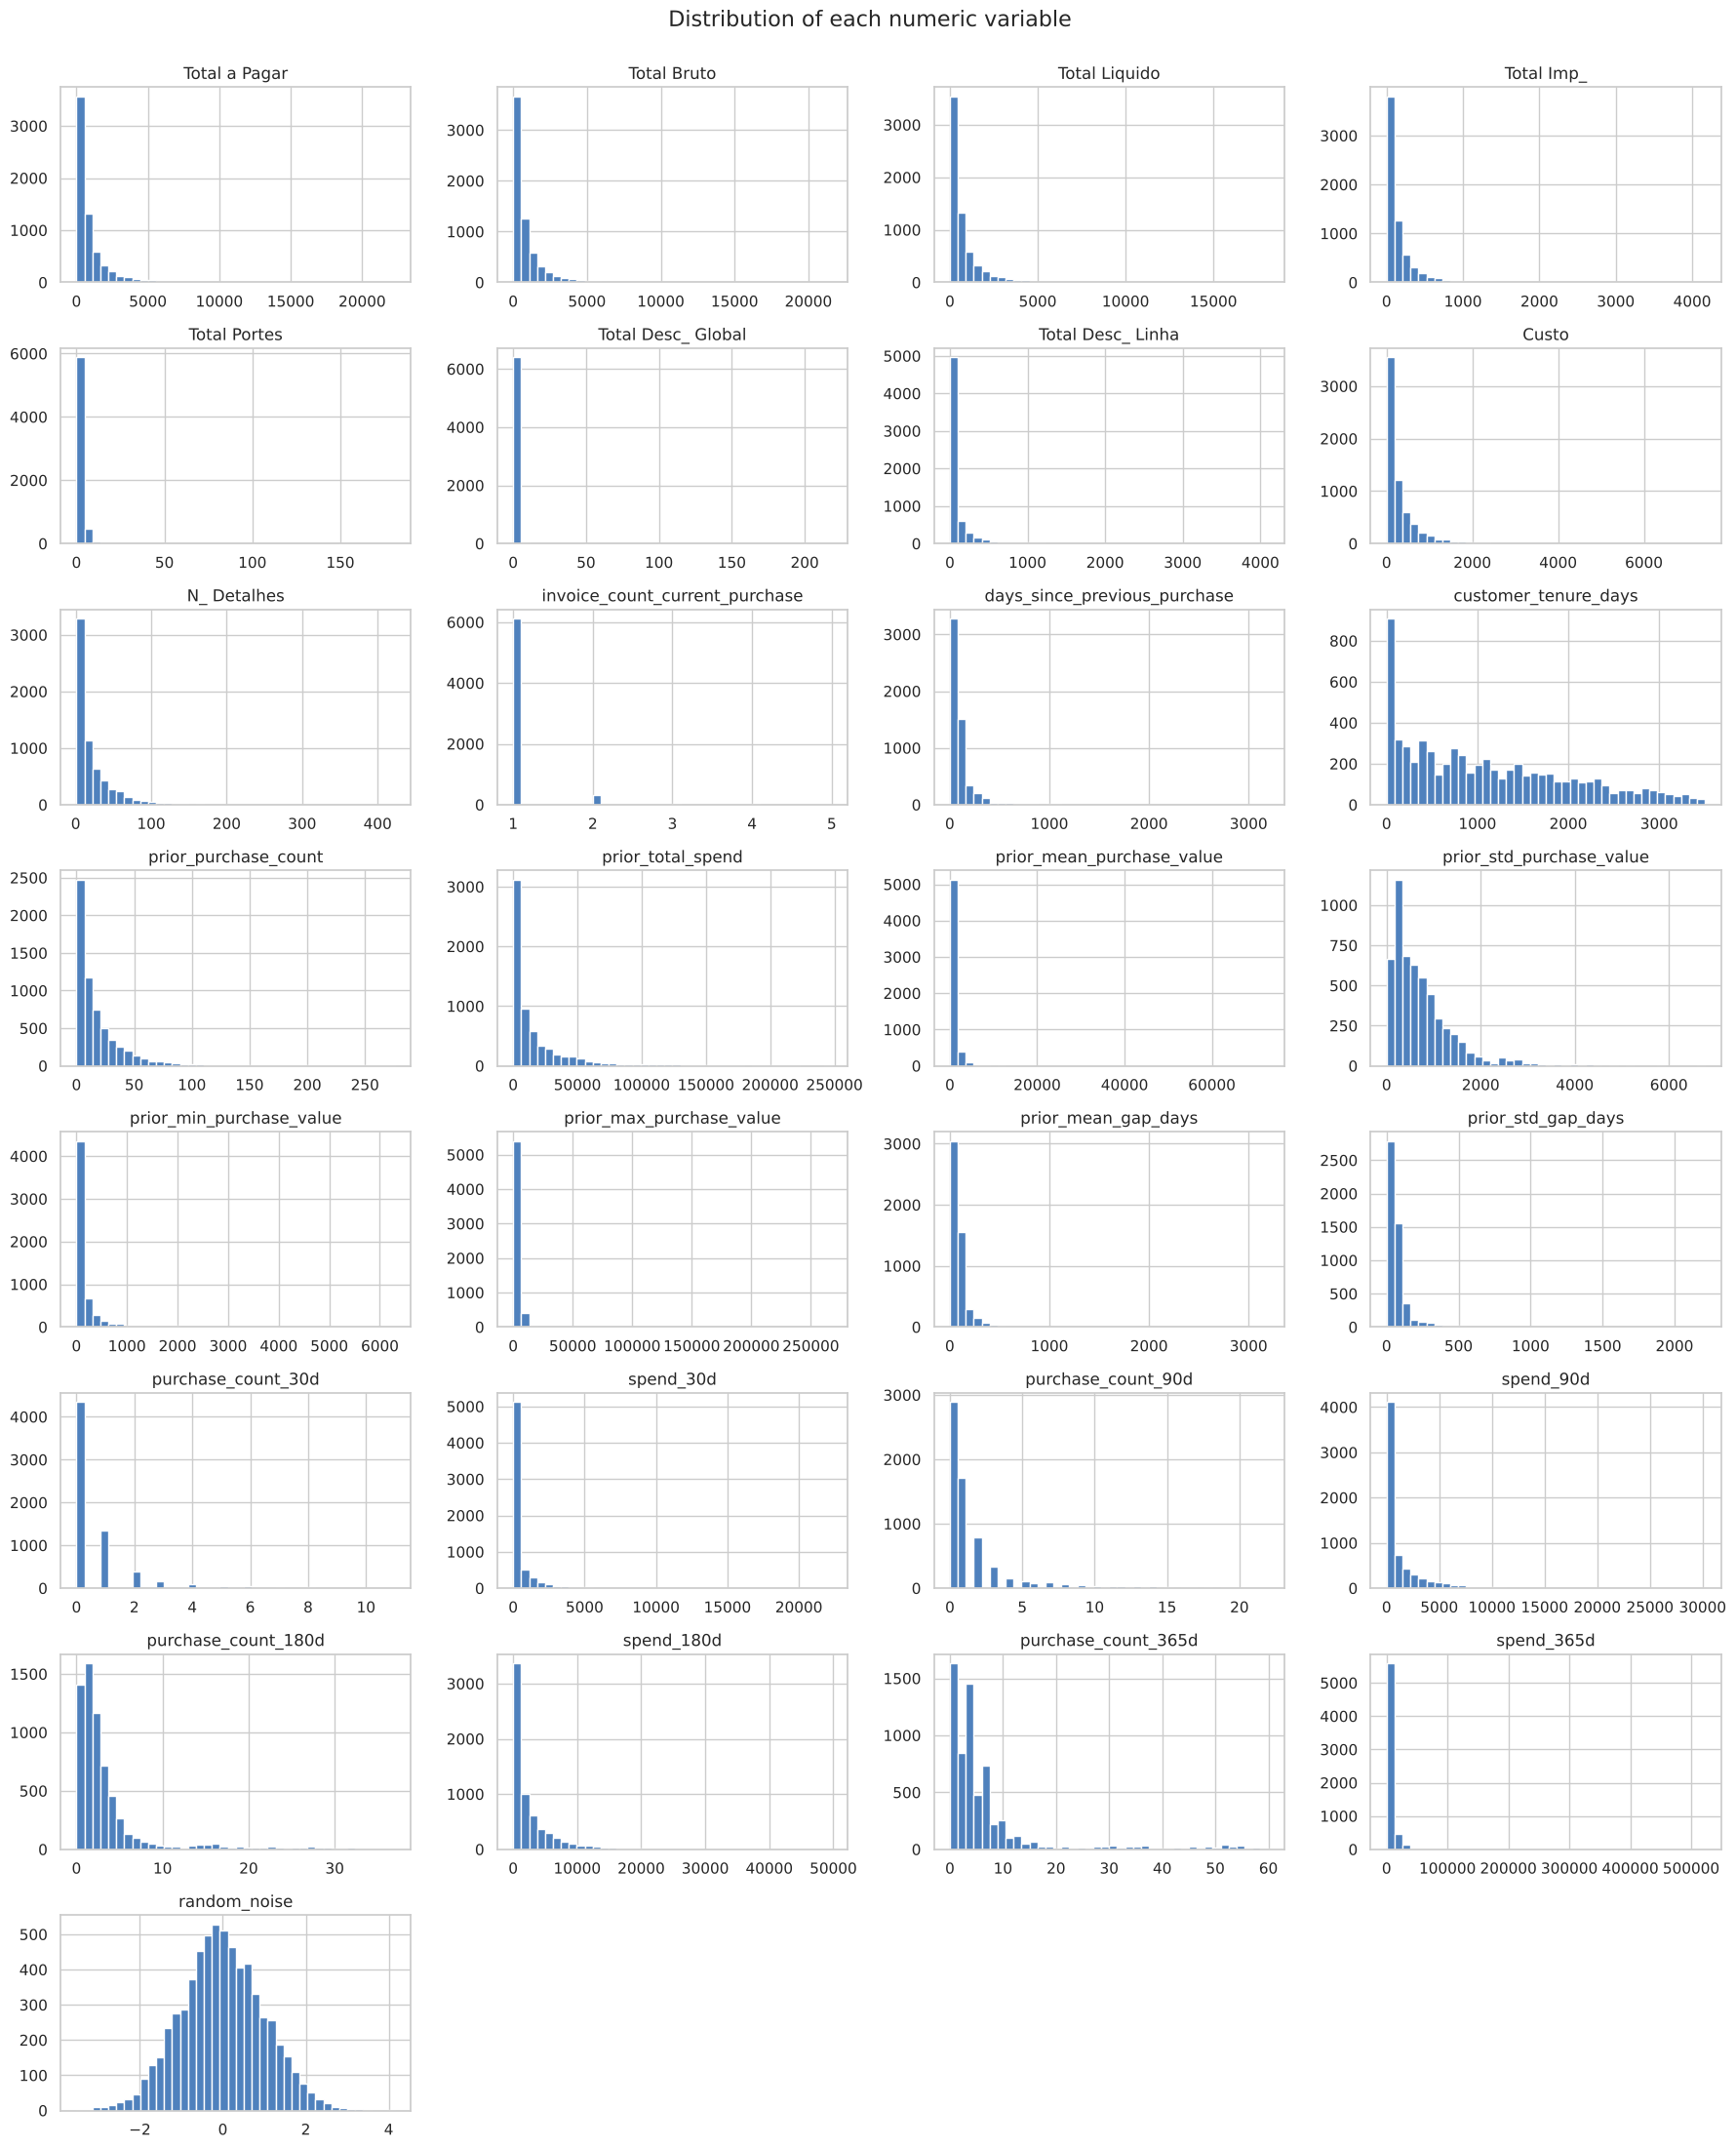

In [20]:
# copy of the numeric variables (non-empty rows only)
plot_num = non_empty[NUM_COLS].copy()

# hide the impossible values from 2.5.4 (negative or >= 100 million); random_noise is allowed to be negative
impossible = (plot_num >= SENTINEL) | (plot_num < 0)
impossible["random_noise"] = False
plot_num = plot_num.mask(impossible)

# one histogram per numeric variable: the height of each bar = how many purchases have values in that range
plot_num.hist(bins=40, figsize=(18, 22), layout=(8, 4), color="#4f81bd")
plt.suptitle("Distribution of each numeric variable", y=1.0, fontsize=16)
plt.tight_layout()
plt.show()

The histograms are easier to compare with two numbers per variable:
- **mean/median** - how many times bigger the mean is than the median; far above 1 means a few very large values pull the mean up;
- **skew** - 0 means the values are spread symmetrically; a large positive number means most values are small
  and a few are very large (a long "tail" to the right). As in the class notebooks, we call a variable
  **skewed when its skew is above 1** (or below −1);
- **% zeros** - how often the variable is exactly 0; if it is almost always 0, the variable barely changes.

In [21]:
# shape of each distribution: mean vs median, skew, and how often the variable is exactly 0
shape = pd.DataFrame({
    "mean/median": (plot_num.mean() / plot_num.median().replace(0, np.nan)).round(2),  # undefined when the median is 0
    "skew": plot_num.skew().round(1),
    "% zeros": ((plot_num == 0).mean() * 100).round(0),
}).sort_values("skew", ascending=False)
display(shape)

# invoice_count_current_purchase only takes 5 values: how often does each appear?
print("invoice_count_current_purchase (% of rows):")
print((plot_num["invoice_count_current_purchase"].value_counts(normalize=True) * 100).round(1))

,mean/median,skew,% zeros
Total Desc_ Global,NaN,27.5,98.0
prior_max_purchase_value,1.65,21.3,0.0
prior_mean_purchase_value,1.32,21.2,0.0
Total Portes,NaN,19.5,84.0
spend_365d,2.38,18.6,13.0
prior_mean_gap_days,1.40,9.3,0.0
prior_std_gap_days,1.46,7.8,0.0
days_since_previous_purchase,1.79,6.5,0.0
invoice_count_current_purchase,1.07,6.4,0.0
prior_min_purchase_value,2.88,5.9,0.0


invoice_count_current_purchase (% of rows):
invoice_count_current_purchase
1.0    94.5
2.0     4.8
4.0     0.3
3.0     0.2
5.0     0.1
Name: proportion, dtype: float64


The same idea as a picture, for the amount of the purchase: the median sits where most purchases are, the mean is pulled to the right by the few very large ones.

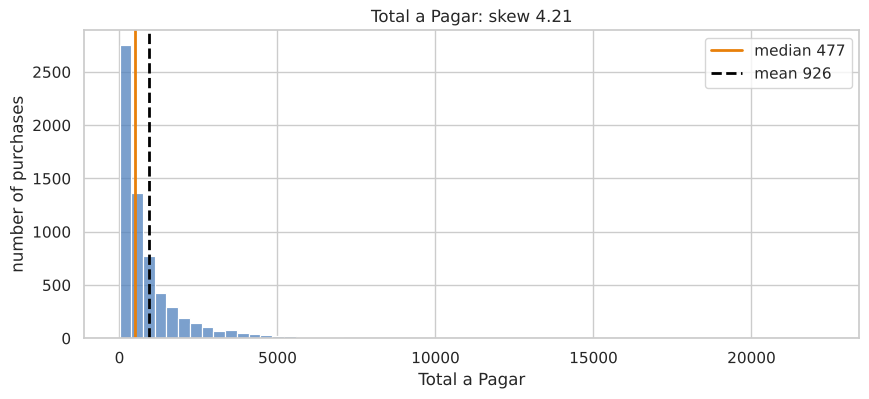

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(plot_num["Total a Pagar"].dropna(), bins=60, color="#4f81bd", ax=ax)
ax.axvline(plot_num["Total a Pagar"].median(), color="#E8800A", lw=2,
           label=f"median {plot_num['Total a Pagar'].median():.0f}")
ax.axvline(plot_num["Total a Pagar"].mean(), color="black", lw=2, ls="--",
           label=f"mean {plot_num['Total a Pagar'].mean():.0f}")
ax.set(xlabel="Total a Pagar", ylabel="number of purchases",
       title=f"Total a Pagar: skew {plot_num['Total a Pagar'].skew():.2f}")
ax.legend()
plt.show()

**What we learn:**
- **Most money and count variables have a long tail to the right** (skew above 1): most purchases are small, but a few are very large. This is normal for sales data. Some models, such as logistic regression, work better when variables are more symmetric and on similar scales, so in initial preprocessing we will consider transforming them. Skewed variables also matter for filling in missing values: their mean is pulled up by the few very large values, so the **median** is a better fill than the mean.
- **Some variables are almost always the same value:**
  - `Total Desc_ Global` is 0 in 98 % of purchases (almost no purchase has a global discount);
  - `Total Portes` is 0 in 84 % (shipping is rarely charged);
  - `invoice_count_current_purchase` is 1 in about 95 % (almost every purchase has a single invoice);
  - `purchase_count_30d` and `spend_30d` are 0 in 67 % (two thirds of purchases had no other purchase in the previous 30 days).

  A variable that barely changes can hardly help the model tell the two classes apart.
- `customer_tenure_days` is the most evenly spread variable: there are customers of all "ages", from new to more than 9 years.
- `random_noise` has a symmetric bell shape centred on 0 – again what we would expect from random numbers.

### 2.6.2 Outliers: the 1.5 × IQR rule (boxplot)

A common way to find outliers is the **boxplot rule**. The "box" goes from the first quartile (Q1, 25 %) to the third quartile (Q3, 75 %); its width is the **IQR** (interquartile range = Q3 − Q1). Any value more than 1.5 × IQR below Q1 or above Q3 is called an outlier.

The rule assumes the variable has a "middle" (a box with some width). Let's see how many purchases it flags per variable.

In [23]:
# quartiles and IQR of each numeric variable (impossible values already hidden in plot_num)
q1, q3 = plot_num.quantile(0.25), plot_num.quantile(0.75)
iqr = q3 - q1

# a value is flagged when it is outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
flagged = (plot_num < q1 - 1.5 * iqr) | (plot_num > q3 + 1.5 * iqr)

pd.DataFrame({
    "Q1": q1, "Q3": q3, "IQR": iqr,
    "% flagged": (flagged.sum() / plot_num.notna().sum() * 100).round(1),
}).sort_values("% flagged", ascending=False).round(2)

,Q1,Q3,IQR,% flagged
spend_30d,0.00,338.24,338.24,16.4
Total Portes,0.00,0.00,0.00,16.3
Total Desc_ Linha,0.00,92.28,92.28,12.7
prior_min_purchase_value,15.45,162.61,147.16,11.4
purchase_count_180d,1.00,3.00,2.00,11.4
spend_90d,0.00,1514.56,1514.56,10.2
prior_total_spend,1505.55,21642.32,20136.77,9.9
Total a Pagar,188.92,1087.67,898.75,9.2
prior_std_gap_days,32.74,78.63,45.89,9.1
Total Liquido,154.38,903.37,748.99,9.1


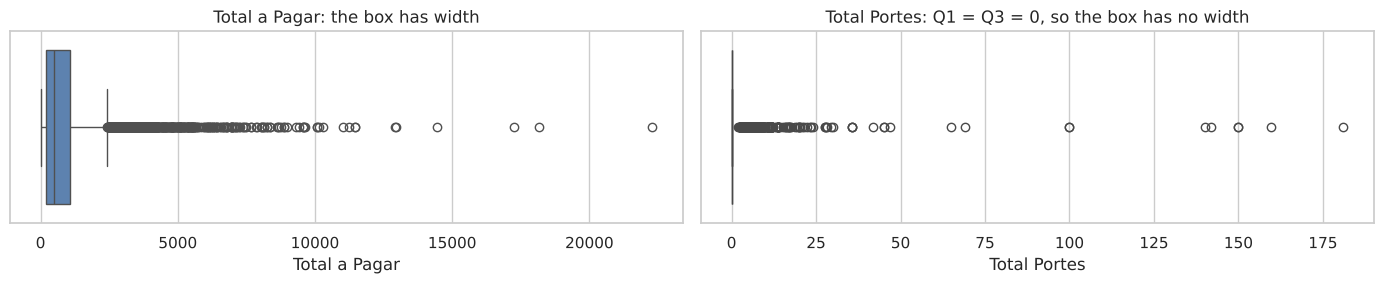

In [24]:
# the rule on a variable with a "middle" (left) and on a variable that is almost always 0 (right)
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
sns.boxplot(x=plot_num["Total a Pagar"], color="#4f81bd", ax=axes[0])
axes[0].set_title("Total a Pagar: the box has width")
sns.boxplot(x=plot_num["Total Portes"], color="#E8800A", ax=axes[1])
axes[1].set_title("Total Portes: Q1 = Q3 = 0, so the box has no width")
plt.tight_layout()
plt.show()

**What we learn:**
- For most variables the rule flags 5-16 % of the purchases. These are not errors: they are the **large purchases and very active customers** in the long right tail we saw above. Removing them would remove real, and probably important, customers.
- The rule **does not work** for variables that are almost always the same value. In `Total Portes`, `Total Desc_ Global`
  and `invoice_count_current_purchase`, Q1 = Q3, so the IQR is 0 and *every* value different from the usual one is flagged
  (for example, every purchase that paid any shipping). As in class: a diagnostic is only valid where its assumption holds.

Conclusion: we will **not delete outliers**. The truly wrong values were already identified in 2.5.4 (impossible values).

### 2.6.3 Categorical variables

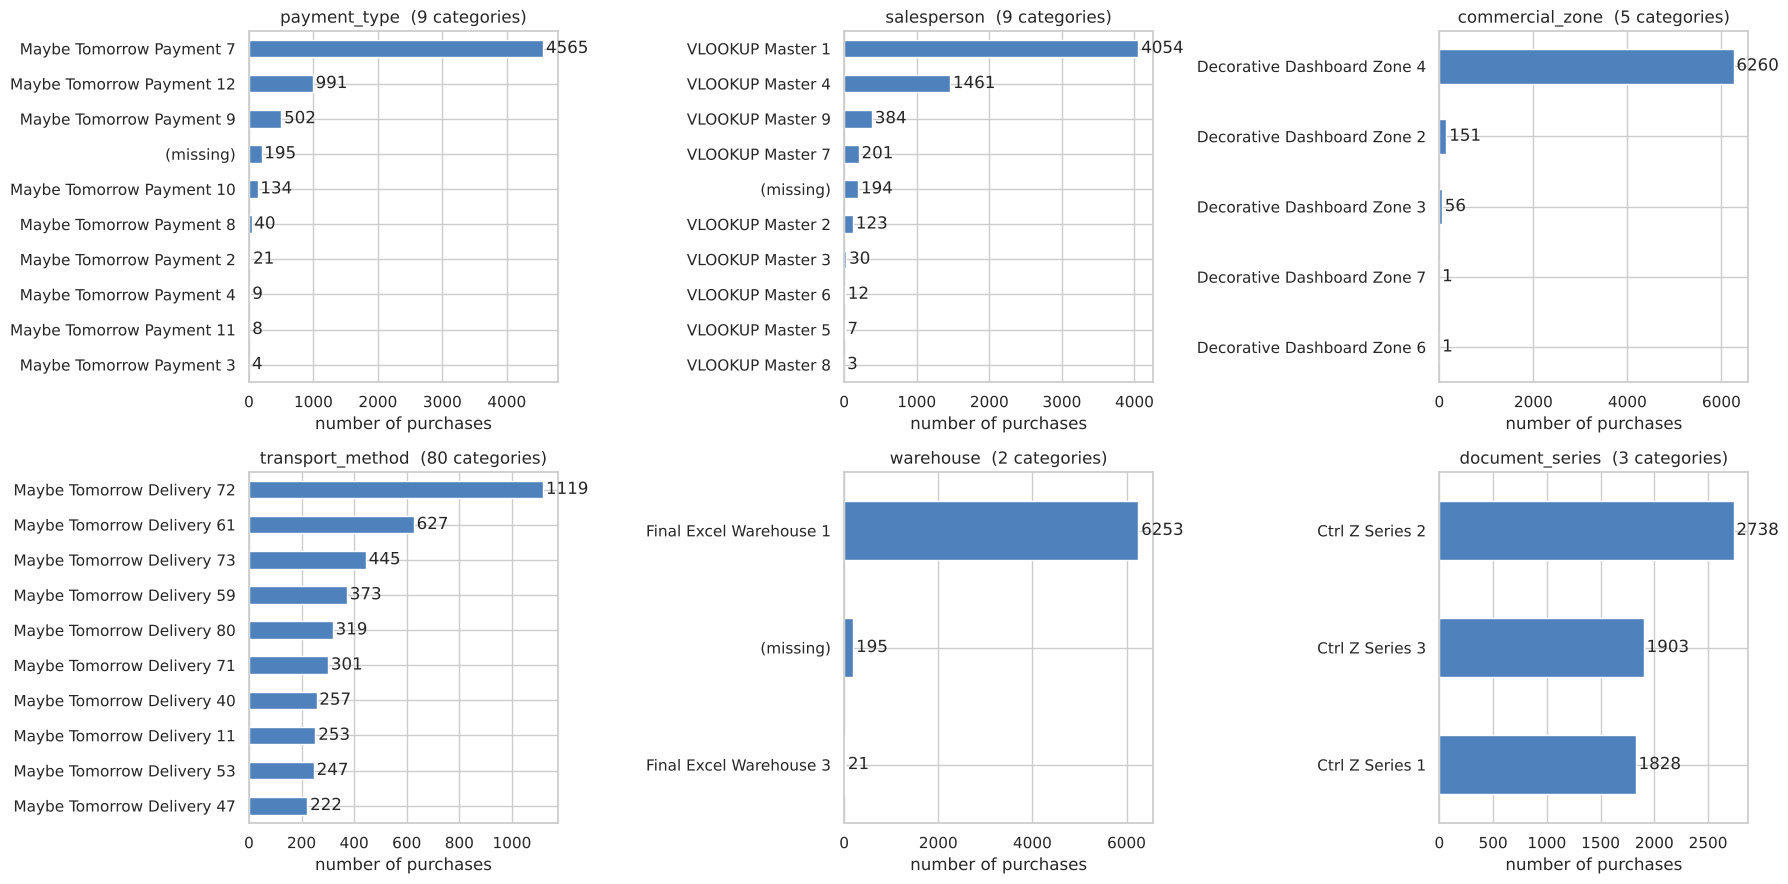

,n_categories,most common,% of rows with it
payment_type,9,Maybe Tomorrow Payment 7,71
salesperson,9,VLOOKUP Master 1,63
commercial_zone,5,Decorative Dashboard Zone 4,97
transport_method,80,Maybe Tomorrow Delivery 72,17
warehouse,2,Final Excel Warehouse 1,97
document_series,3,Ctrl Z Series 2,42


In [25]:
# one bar chart per categorical variable (only the 10 most frequent categories, because transport_method has ~80)
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, CAT_COLS):
    counts = non_empty[col].fillna("(missing)").value_counts()
    counts.head(10).sort_values().plot.barh(ax=ax, color="#4f81bd")
    ax.bar_label(ax.containers[0], padding=2)                     # number of purchases on each bar
    ax.set_title(f"{col}  ({non_empty[col].nunique()} categories)")
    ax.set_xlabel("number of purchases")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

# number of categories and share of the most frequent one
pd.DataFrame({
    "n_categories": non_empty[CAT_COLS].nunique(),
    "most common": non_empty[CAT_COLS].mode().iloc[0],
    "% of rows with it": [round(non_empty[c].value_counts().iloc[0] / len(non_empty) * 100) for c in CAT_COLS],
})

**What we learn:**
- The category names are anonymised (e.g. "Maybe Tomorrow Payment 7"), so we cannot know what they mean, only how often they appear. The numbers in the names are labels, not quantities (like the IDs).
- `commercial_zone` and `warehouse` are **almost constant**: one category covers about 97 % of the purchases.
- `payment_type` and `salesperson` are dominated by one or two categories, plus several **rare categories**
  with only a handful of purchases.
- `transport_method` has about 80 categories, many of them tiny. That is too many to turn into separate columns one by one, so in initial preprocessing we will probably group the rare categories into an "Other" category.
- `document_series` is the only one with three categories of similar size.

### 2.6.4 Purchases over time

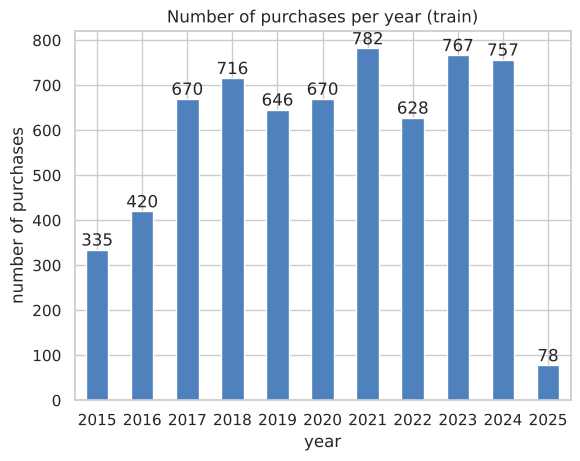

In [26]:
# number of purchases per year in train
years = pd.to_datetime(non_empty["purchase_date"]).dt.year
ax = years.value_counts().sort_index().plot.bar(color="#4f81bd", rot=0)
ax.bar_label(ax.containers[0])
ax.set(title="Number of purchases per year (train)", xlabel="year", ylabel="number of purchases")
plt.show()

**What we learn:** the training data covers almost 10 years. 2015 and 2025 look small only because they are
incomplete (train starts in July 2015 and ends in February 2025). Between 2017 and 2024 the number of purchases
is fairly stable (about 630-780 per year), so there is no sudden change that would make the older data useless.

## <font color='#E8800A'>2.7 Relationship with the target</font> <a class="anchor" id="s1-7"></a>


Now the most important question: **which variables are different for customers who bought again (1) and those who did not (0)?**
A variable whose values differ between the two groups can help the model; a variable that looks the same in both groups probably cannot.

### 2.7.1 Numeric variables

Let's compare each variable between the two groups.
We use:
- the **median** of each group (better than the mean for skewed variables, see 2.6.1);
- the **correlation with the target**, a number between −1 and 1: 0 means no relationship, a positive value means "higher values → more likely to buy again", a negative value means "higher values → less likely".

In [27]:
# the target, for the same (non-empty) rows as plot_num
y = non_empty[TARGET]

# median of each variable in each group, and correlation with the target
by_class = pd.DataFrame({
    "median (0: did not buy again)": plot_num[y == 0].median(),
    "median (1: bought again)": plot_num[y == 1].median(),
    "correlation with target": plot_num.corrwith(y),
}).round(2)

# sorted from the most negative to the most positive relationship
by_class.sort_values("correlation with target")

,median (0: did not buy again),median (1: bought again),correlation with target
prior_mean_gap_days,101.75,55.76,-0.24
days_since_previous_purchase,105.00,37.00,-0.20
prior_std_gap_days,65.06,43.62,-0.20
prior_min_purchase_value,88.11,45.51,-0.10
random_noise,-0.04,-0.05,-0.01
Total Desc_ Global,0.00,0.00,-0.01
Total Portes,0.00,0.00,-0.00
N_ Detalhes,12.00,10.00,0.02
prior_mean_purchase_value,632.41,789.94,0.03
invoice_count_current_purchase,1.00,1.00,0.05


The boxplots below compare the two groups for the 6 variables most related to the target (outliers hidden so that the boxes are readable).

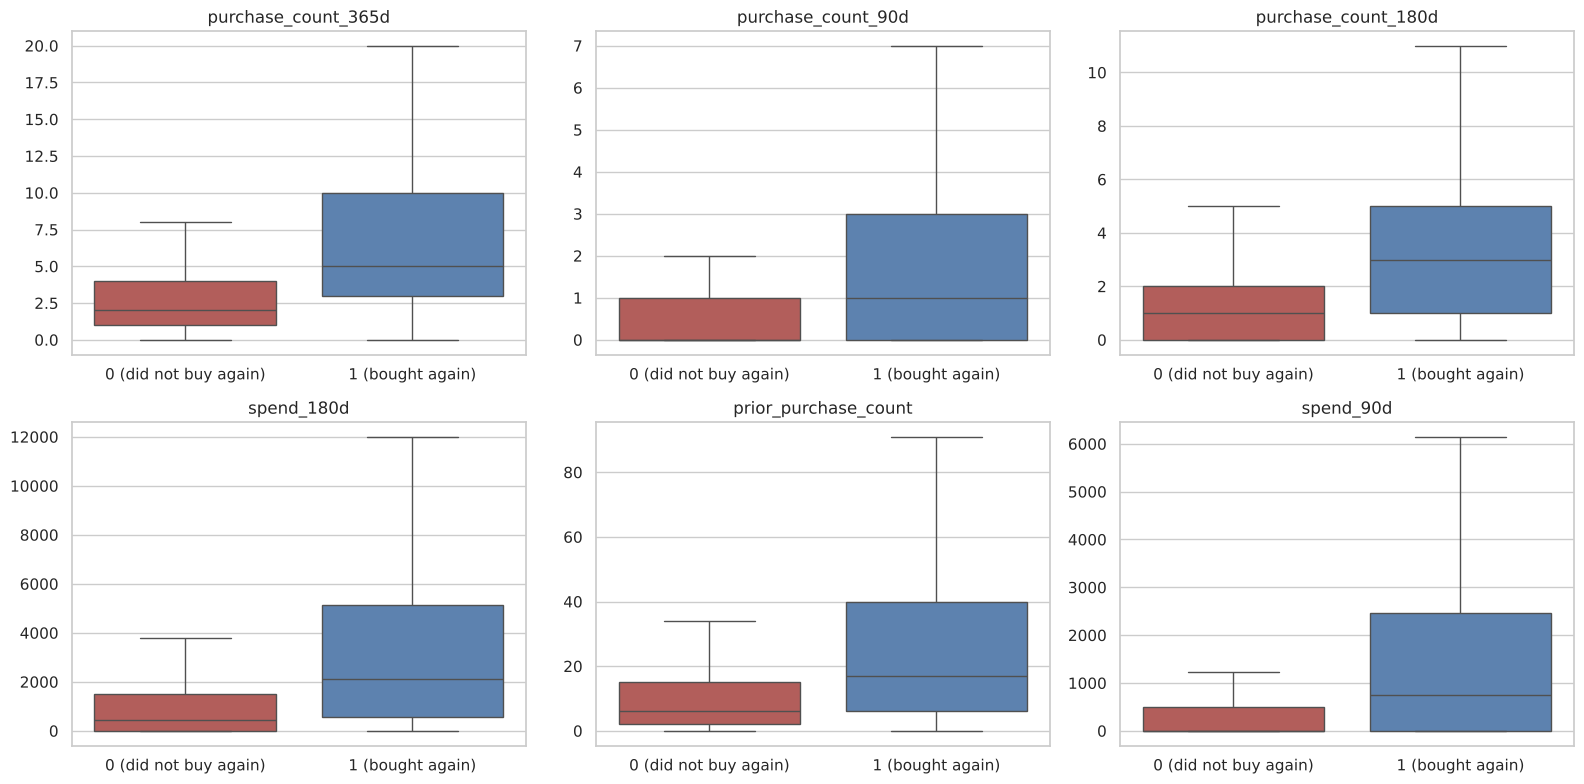

Repeat rate for first purchases: 33% | for customers with previous purchases: 58%


In [28]:
# the 6 variables with the strongest relationship (largest correlation, positive or negative)
top6 = by_class["correlation with target"].abs().sort_values(ascending=False).head(6).index

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, top6):
    sns.boxplot(x=y, y=plot_num[col], hue=y, palette=["#c0504d", "#4f81bd"], legend=False,
                showfliers=False, ax=ax)
    ax.set_xticks([0, 1], labels=["0 (did not buy again)", "1 (bought again)"])
    ax.set(title=col, xlabel="", ylabel="")
plt.tight_layout()
plt.show()

# first purchases vs. customers with previous purchases
first = non_empty["prior_purchase_count"] == 0
print(f"Repeat rate for first purchases: {y[first].mean():.0%} | "
      f"for customers with previous purchases: {y[~first].mean():.0%}")

**What we learn:**
- **How often the customer buys is what matters most.** Customers who bought again had bought much more often before:
  a median of 5 purchases in the last year against 2, and 17 previous purchases against 6 (correlation about +0.3).
  The same holds for the spend in the last 90, 180 and 365 days.
- **How long since the last purchase matters too (in the opposite direction).** For those who bought again, the median time
  since the previous purchase is 37 days, against 105 for those who did not; their usual gap between purchases is about 56 days against 102. This makes sense: a customer who usually buys every two months is likely to buy again within 90 days.
- **First-time buyers come back much less:** only 33 % of first purchases are followed by another one, against 58 % for
  customers who had bought before. So the "first purchase" column planned in 2.5.3 should also help the model.
- **The amounts of the current purchase matter little** (correlation below 0.1): how big this purchase is says little about whether the customer will come back.
- `random_noise`, `Total Portes` and `Total Desc_ Global` have a correlation of about 0: **no relationship with the target**. This confirms that `random_noise` is, in fact, just noise.

### 2.7.2 Categorical variables

For categorical variables we look at the **repeat rate** of each category: the % of purchases in that category that were
followed by another purchase within 90 days. If the rate changes a lot from one category to another, the variable is useful.
To summarise this with one number per variable we use **Cramér's V** again (as in class, week 4), now between each variable
and the target (0 = no link, 1 = perfect link).

,Cramer's V,p-value,min expected count
variable,,,
transport_method,0.285,4.900000e-67,0.44
payment_type,0.234,7.300000e-71,1.76
salesperson,0.201,5.300000e-51,1.32
commercial_zone,0.064,2.800000e-05,0.44
warehouse,0.040,6.200000e-03,9.25
document_series,0.003,9.700000e-01,804.78


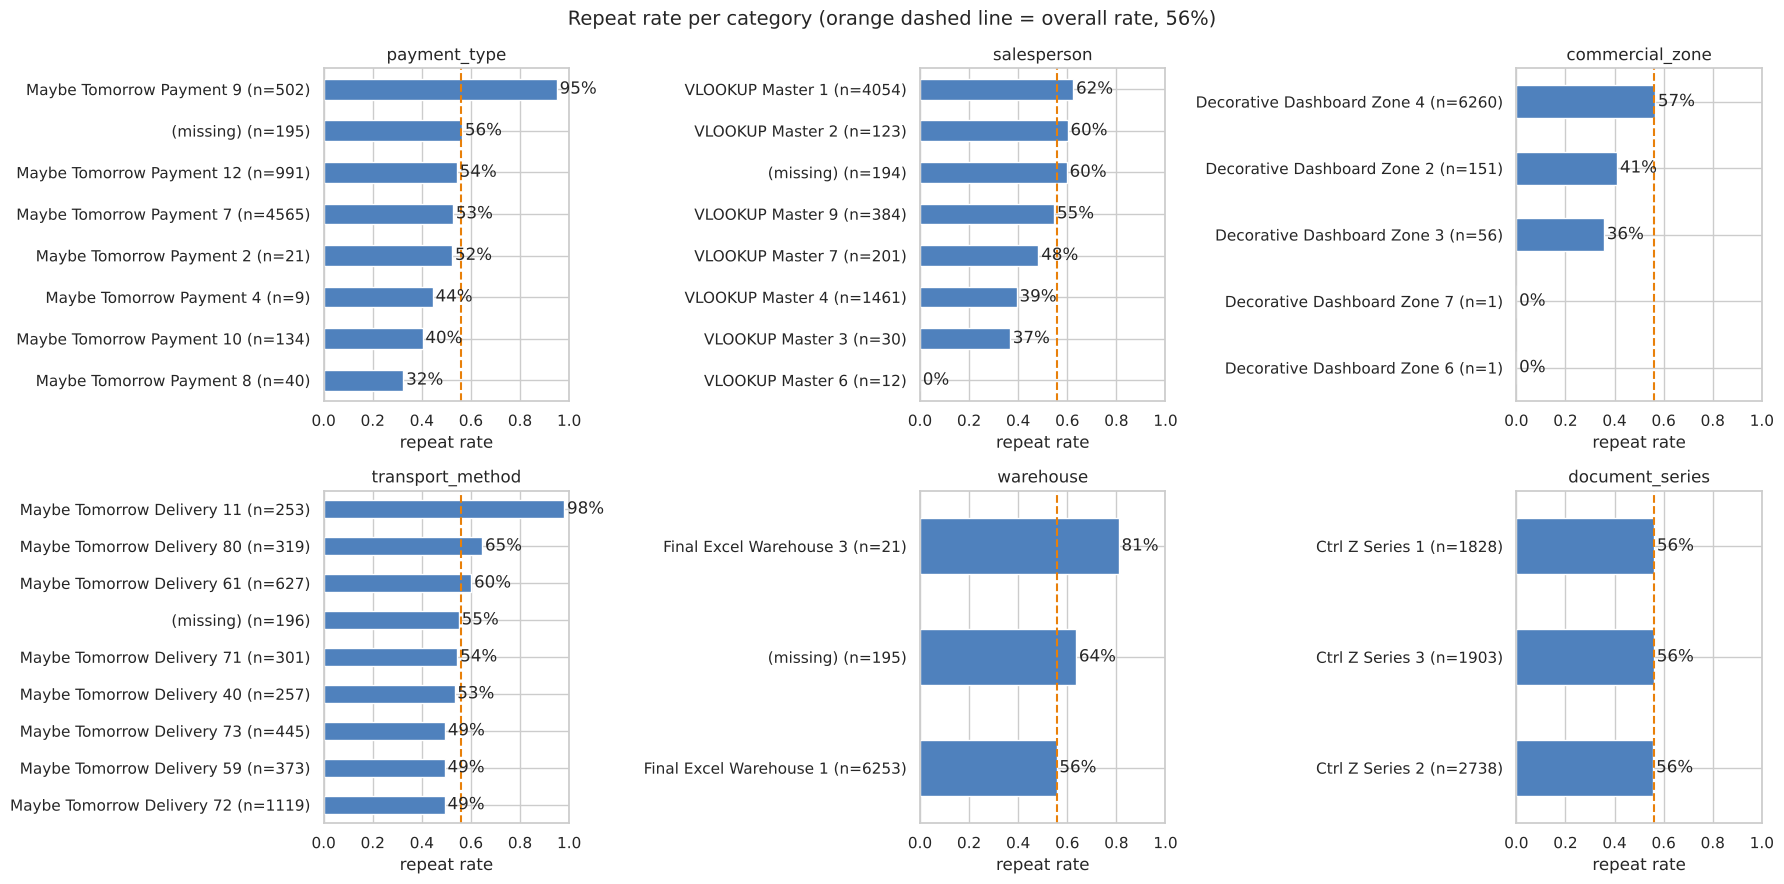

In [29]:
# Cramér's V between each categorical variable and the target
rows = []
for col in CAT_COLS:
    table = pd.crosstab(non_empty[col].fillna("(missing)"), y)   # count of 0s and 1s per category (gaps as their own category)
    chi2, p, _, expected = chi2_contingency(table)
    rows.append({"variable": col,
                 "Cramer's V": round(association(table, method="cramer", correction=True), 3),
                 "p-value": float(f"{p:.2g}"),
                 "min expected count": round(expected.min(), 2)})
display(pd.DataFrame(rows).set_index("variable").sort_values("Cramer's V", ascending=False))

# repeat rate of the 8 most frequent categories of each variable, plus "(missing)" (n = number of purchases)
overall = y.mean()
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, CAT_COLS):
    stats = non_empty[col].fillna("(missing)").to_frame().join(y).groupby(col)[TARGET].agg(rate="mean", n="size")
    top = stats.sort_values("n", ascending=False).head(8)
    stats = pd.concat([top, stats.loc[["(missing)"]]]) if "(missing)" in stats.index and "(missing)" not in top.index else top
    stats.index = [f"{name} (n={n})" for name, n in zip(stats.index, stats["n"])]
    stats["rate"].sort_values().plot.barh(ax=ax, color="#4f81bd")
    ax.bar_label(ax.containers[0], labels=[f"{v:.0%}" for v in stats["rate"].sort_values()], padding=2)
    ax.axvline(overall, color="#E8800A", ls="--")                    # overall repeat rate
    ax.set(title=col, xlabel="repeat rate", ylabel="", xlim=(0, 1))
fig.suptitle(f"Repeat rate per category (orange dashed line = overall rate, {overall:.0%})", fontsize=14)
plt.tight_layout()
plt.show()

**What we learn:**
- `transport_method` (V ≈ 0.29), `payment_type` (≈ 0.23) and `salesperson` (≈ 0.20) have the **strongest link** with the target.
  For example, purchases paid with "Payment 9" were followed by another purchase in 95 % of cases (502 purchases), against 53 %
  for the most common payment type; purchases from "VLOOKUP Master 4" only 39 %, against 62 % for "Master 1"; and almost every purchase shipped with
  "Delivery 11" (98 %, 253 purchases) was followed by another one.
- `commercial_zone` and `warehouse` have a weak link – expected, since they are almost constant (2.6.3).
- The missing values, shown as a "(missing)" category, have a repeat rate of 55–64 %, close to the overall 56 %.
  This agrees with 2.5.3 (the gaps look random) and supports filling them with a "missing" category.
- `document_series` has **no link at all**: the repeat rate is 56 % in each of its three categories.
- Careful: the "min expected count" is below 5 for most variables because of the tiny categories, so their p-values are not fully
  reliable. A category with only a few purchases (e.g. 100 % or 0 % with 3 purchases) says nothing. Grouping the rare categories
  into "Other" (planned in 2.6.3) also solves this.

### 2.7.3 Repeat rate over time

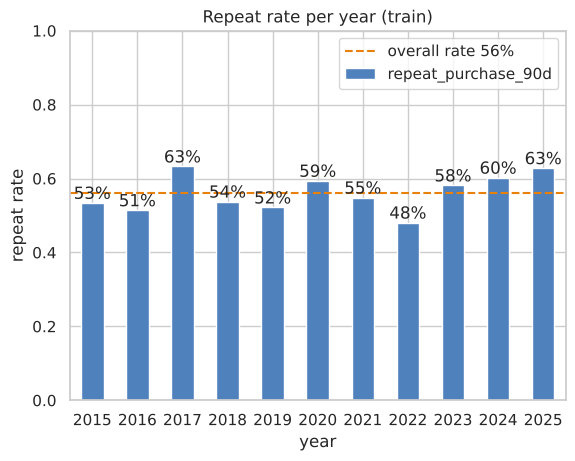

In [30]:
# repeat rate per year (train)
rate_per_year = y.groupby(pd.to_datetime(non_empty["purchase_date"]).dt.year).mean()
ax = rate_per_year.plot.bar(color="#4f81bd", rot=0)
ax.bar_label(ax.containers[0], labels=[f"{v:.0%}" for v in rate_per_year])
ax.axhline(overall, color="#E8800A", ls="--", label=f"overall rate {overall:.0%}")
ax.set(title="Repeat rate per year (train)", xlabel="year", ylabel="repeat rate", ylim=(0, 1))
ax.legend()
plt.show()

**What we learn:** the repeat rate goes up and down between about 48 % and 63 % per year, with no clear trend.
This is good news: since the test set is in the future (2.4), we want the relationship between the variables and the target
to be stable over time.

Besides the year, a date also gives the **month** and the **day of the week**. Do they relate to the target?

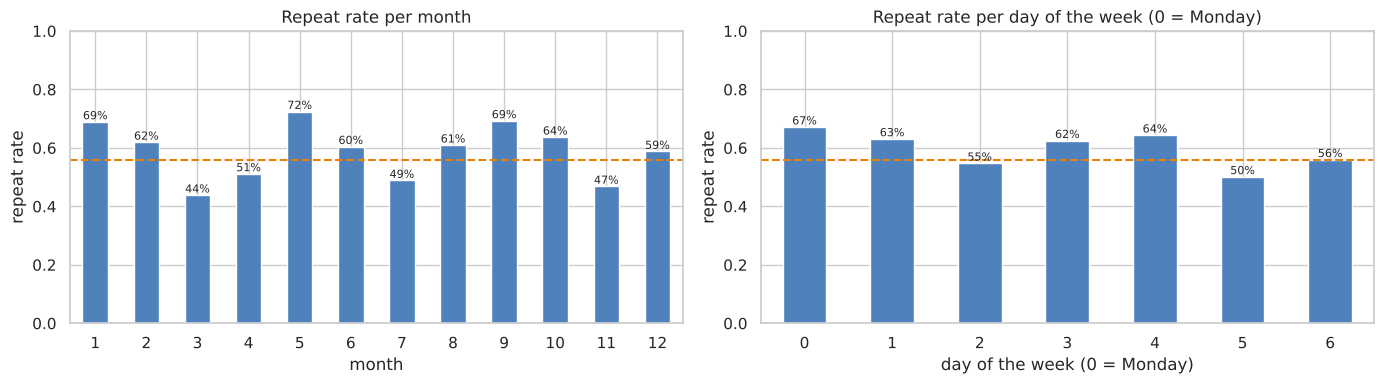

month        Cramér's V = 0.183
day of week  Cramér's V = 0.133
quarter      Cramér's V = 0.033
Purchases per day of the week: {0: 630, 1: 683, 2: 84, 3: 24, 4: 811, 5: 3215, 6: 1022}


In [31]:
# repeat rate per month and per day of the week (train)
purchase_dates = pd.to_datetime(non_empty["purchase_date"])
parts = {"month": purchase_dates.dt.month, "day of the week (0 = Monday)": purchase_dates.dt.dayofweek}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, values) in zip(axes, parts.items()):
    rates = y.groupby(values).mean()
    rates.plot.bar(ax=ax, color="#4f81bd", rot=0)
    ax.bar_label(ax.containers[0], labels=[f"{v:.0%}" for v in rates], fontsize=8)
    ax.axhline(overall, color="#E8800A", ls="--")               # overall repeat rate
    ax.set(title=f"Repeat rate per {name}", xlabel=name, ylabel="repeat rate", ylim=(0, 1))
plt.tight_layout()
plt.show()

# Cramér's V of each date part with the target, and number of purchases per day of the week
for name, values in [("month", purchase_dates.dt.month), ("day of week", purchase_dates.dt.dayofweek),
                     ("quarter", purchase_dates.dt.quarter)]:
    print(f"{name:12s} Cramér's V = {association(pd.crosstab(values, y), method='cramer', correction=True):.3f}")
print("Purchases per day of the week:", purchase_dates.dt.dayofweek.value_counts().sort_index().to_dict())

**What we learn:**
- **Month** is linked to the target (V ≈ 0.18): the repeat rate goes from about 44 % (March) to 72 % (May).
- **Day of the week** has a weaker link (V ≈ 0.13). Purchases are very unevenly spread (most on Saturdays, almost none on Wednesdays and Thursdays), which suggests the dates may have been shifted when the data was anonymised.
- **Quarter** has no link (V ≈ 0.03), and the **year** shows no trend. The year is also risky: the test purchases are in 2025-2026, years the model never sees in train.

Decision: month and day of the week are candidate features (as categories, since "month 12" is not "twelve times month 1");
year and quarter are not used.

## <font color='#E8800A'>2.8 Correlations between variables</font> <a class="anchor" id="s1-8"></a>


Two variables that are very strongly correlated carry almost the same information, so the model does not need both.
We compute the correlation between every pair of numeric variables (as in class, with `.corr()`).

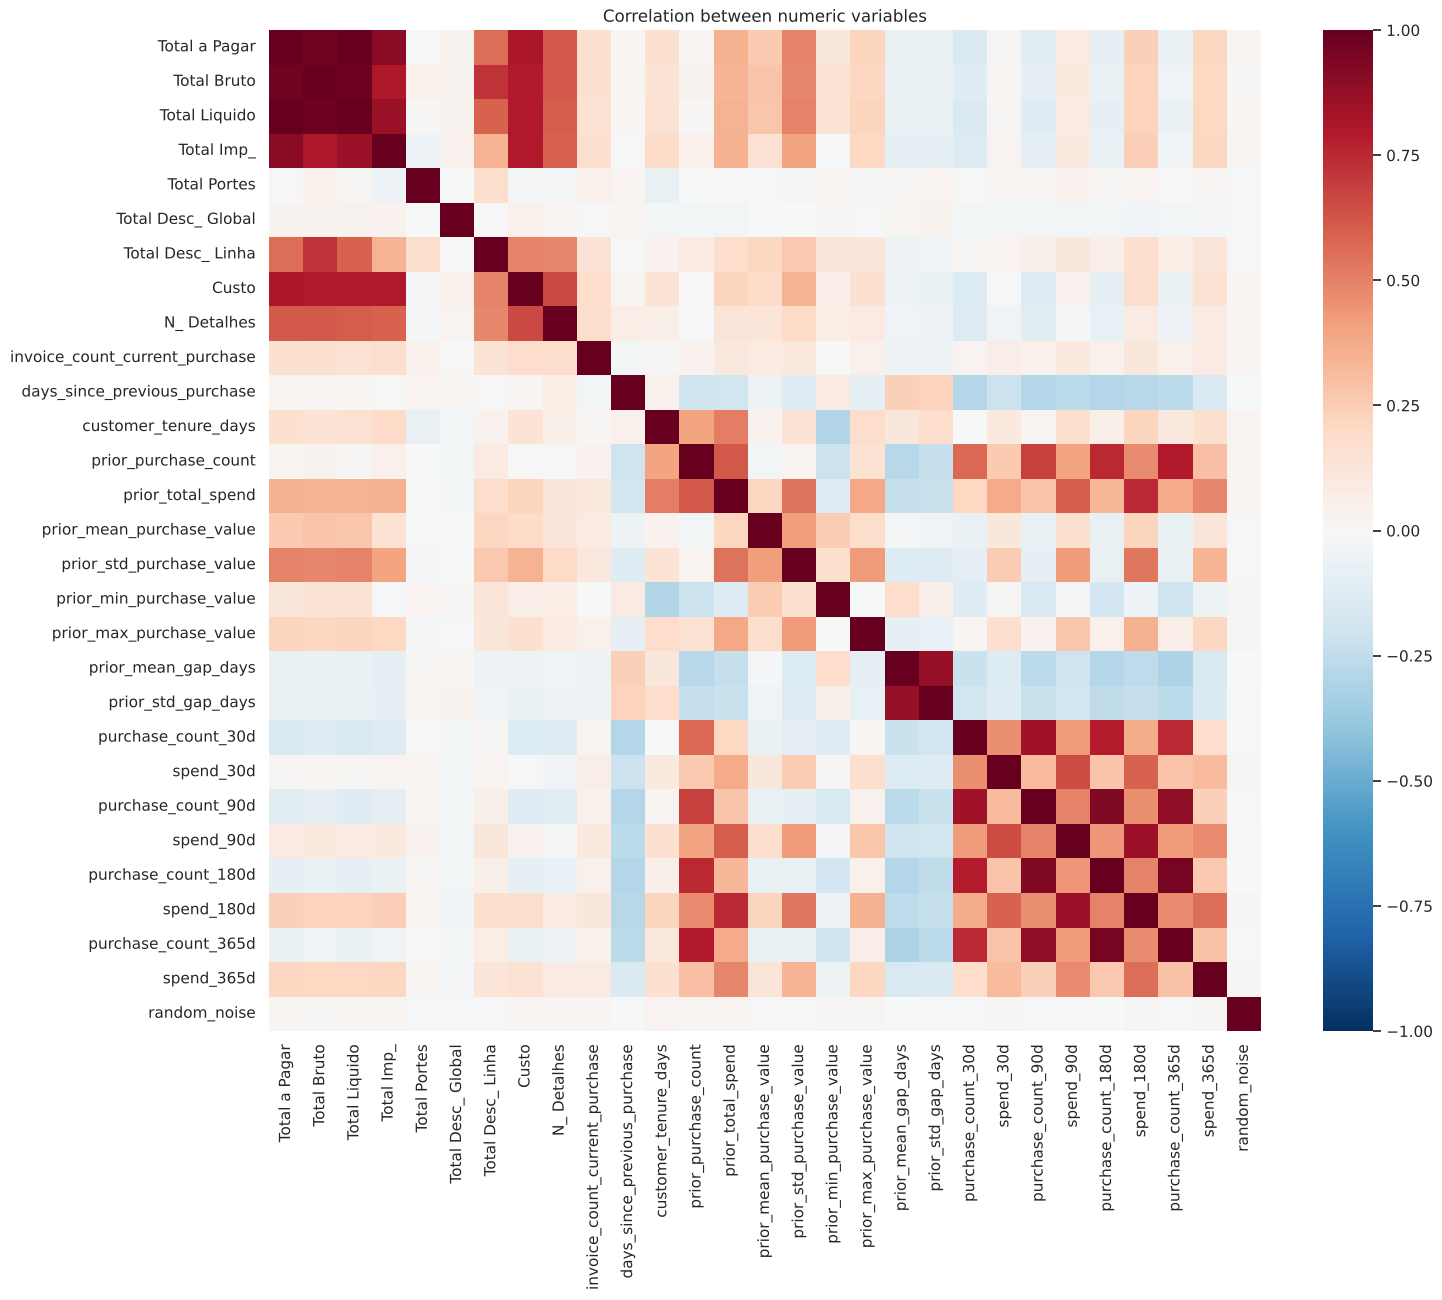

In [32]:
# correlation between every pair of numeric variables (impossible values hidden)
corr = plot_num.corr()

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)   # red = positive, blue = negative
ax.set_title("Correlation between numeric variables")
plt.show()

In [33]:
# pairs with a very strong correlation (|r| >= 0.8), each pair listed once
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
display(pairs[pairs.abs() >= 0.8].sort_values(ascending=False).round(2).to_frame("correlation"))

# strongest correlation of random_noise with any other variable
print("Largest |correlation| of random_noise with another variable:",
      round(corr["random_noise"].drop("random_noise").abs().max(), 3))

,,correlation
Total a Pagar,Total Liquido,1.00
Total Bruto,Total Liquido,0.98
Total a Pagar,Total Bruto,0.97
purchase_count_180d,purchase_count_365d,0.95
purchase_count_90d,purchase_count_180d,0.94
Total a Pagar,Total Imp_,0.90
purchase_count_90d,purchase_count_365d,0.88
prior_mean_gap_days,prior_std_gap_days,0.87
Total Liquido,Total Imp_,0.86
spend_90d,spend_180d,0.86


Largest |correlation| of random_noise with another variable: 0.029


**What we learn:**
- **Invoice amounts:** `Total a Pagar`, `Total Liquido`, `Total Bruto`, `Total Imp_` and `Custo` are all correlated above 0.8
  (`Total a Pagar` and `Total Liquido`: 1.00), as expected from 2.5.5. One or two of them are enough.
- **Purchase counts in the time windows:** each count is correlated 0.85-0.95 with the next window (30→90→180→365 days), and the 365-day count with `prior_purchase_count` 0.80.
- **Other pairs:** `spend_90d` / `spend_180d` (0.86) and `prior_mean_gap_days` / `prior_std_gap_days` (0.87).
- `random_noise` is not correlated with any other variable.

In feature selection we will keep only one variable from each strongly correlated group, choosing the one most related to the target (2.7).

## <font color='#E8800A'>2.9 The customer table (`clientes.csv`)</font> <a class="anchor" id="s1-9"></a>
[Back to TOC](#toc)

`clientes.csv` is optional: one row per customer, joined through `customer_id`. We only need to decide **whether** it is worth adding, so a quick look is enough.

Just from the column names, the table has three kinds of information:
- **where the customer is** - `country_or_region`, `commercial_region`, `island`, `municipality`, `city`, `postal_area`,
  `postal_code`, `street`, `address`;
- **who the customer is** - `company_name`;
- **customer profile** - `customer_type`, `customer_since_year`.

None of them describes purchasing behaviour, which is what the target is about, and the train file already has a location variable (`commercial_zone`) and the customer's age (`customer_tenure_days`). So we expect pretty much nothing from this table, let's see below if there is any relevant information.

In [34]:
# one row per column: missing values and number of distinct values (in the table and among the train customers)
train_customers = clientes[clientes["customer_id"].isin(non_empty["customer_id"])]
pd.DataFrame({
    "missing %": (clientes.isna().mean() * 100).round(1),
    "distinct values": clientes.nunique(),
    "distinct among the 610 train customers": train_customers.nunique(),
}).drop(index="customer_id")

,missing %,distinct values,distinct among the 610 train customers
country_or_region,0.0,11,7
commercial_region,10.0,37,32
island,50.6,10,10
municipality,13.9,183,150
city,47.8,417,259
postal_area,6.2,271,188
postal_code,14.9,828,516
street,52.3,511,264
address,0.5,1120,597
customer_type,100.0,0,0


In [35]:
# attach the customer table to each (non-empty) purchase
joined = non_empty[["customer_id", "customer_tenure_days", "commercial_zone", "purchase_date"]].merge(
    clientes, on="customer_id", how="left")
print("Train customers found in clientes:", f"{non_empty['customer_id'].isin(clientes['customer_id']).mean():.0%}",
      "| test customers:", f"{test['customer_id'].isin(clientes['customer_id']).mean():.0%}")

# compare with what train already has
years_as_customer = pd.to_datetime(joined["purchase_date"]).dt.year - joined["customer_since_year"]
print("Correlation customer_since_year (as years as customer) vs customer_tenure_days:",
      round(years_as_customer.corr(joined["customer_tenure_days"]), 2))
for col in ["country_or_region", "commercial_region"]:
    table = pd.crosstab(joined[col].fillna("(missing)"), joined["commercial_zone"].fillna("(missing)"))
    print(f"Cramér's V between {col} and commercial_zone (train): {association(table, method='cramer'):.2f}")

Train customers found in clientes: 100% | test customers: 100%
Correlation customer_since_year (as years as customer) vs customer_tenure_days: 0.92
Cramér's V between country_or_region and commercial_zone (train): 0.89
Cramér's V between commercial_region and commercial_zone (train): 0.65


**What we learn:**
- Every train and test customer is in the table, so a join would be possible.
- `customer_type` is **completely empty**.
- The address columns and `company_name` have hundreds of different values among only 610 customers – some almost one per
  customer. They mostly **identify the customer** (like `customer_id`, 2.5.6) rather than describe it, and several are
  about half empty.
- What is left mostly **repeats information we already have**: `customer_since_year` is strongly correlated with
  `customer_tenure_days` (0.92), and `country_or_region` and `commercial_region` are clearly related to `commercial_zone`
  from train (Cramér's V 0.89 and 0.65).

**Decision:** from `clientes.csv` we only add **`commercial_region`** –> the one column that is not a customer identifier, is mostly filled in (10 % missing) and is only partly covered by `commercial_zone`. The other columns are not used.
Whether it really helps is measured in Section III (3.4).

## <font color='#E8800A'>2.10 Exploration summary: findings and preprocessing decisions</font> <a class="anchor" id="eda-summary"></a>


| Problem | Where | What we plan to do |
|---|---|---|
| 65 rows with no information | train only | remove them |
| Empty history for first purchases (expected, MAR) | history columns | add a "first purchase" indicator and fill in the gaps |
| Values that were simply not recorded (~3 % per column, look MCAR) | `spend_365d`, 4 categorical columns | fill them in (median / most frequent or "missing" category), using only information from train (see intro) |
| Impossible values (−4 days, negative money, 1,000,000,000) | 4 numeric columns, in train **and** test | treat them as missing and fill them in |
| Groups of strongly correlated variables (correlation ≥ 0.8, see 2.8) | invoice amounts (`Total *`, `Custo`); purchase counts 90/180/365d; `spend_90d`/`spend_180d`; gap days | keep one per group in feature selection |
| Identifier columns | `ID`, `customer_id` | do not use them as features |
| Column that looks like random numbers (average 0, std 1) and is not related to the target (2.7) | `random_noise` | drop it in feature selection |
| Date stored as text; month and day of the week linked to the target, year not (2.7.3) | `purchase_date` | convert it to a real date; create month and day of the week as categories; do not use year or quarter |
| Skewed variables (skew > 1): long tail of very large values | all money and count variables | fill gaps with the median (not the mean); consider `log1p` and scaling |
| Almost constant variables | `commercial_zone`, `warehouse`, `Total Desc_ Global`, `invoice_count_current_purchase` | probably little information – check in feature selection |
| Many rare categories | `transport_method`, `payment_type`, `salesperson` | group the rare categories into "Other" |
| Many "outliers" by the 1.5 × IQR rule | skewed variables | keep the rows (real large purchases); test capping only the most extreme values in Section III |
| Variables most related to the target | purchase counts and spend in the last 90/180/365 days, `prior_purchase_count` (+); `days_since_previous_purchase`, gap days (−); `transport_method`, `payment_type`, `salesperson` | main candidates for the model – confirm in feature selection |
| Variables with no relationship with the target | `document_series`, `Total Portes`, `Total Desc_ Global` | candidates to drop in feature selection |
| Customer table: mostly customer-identifying columns, one empty column, tenure already known (2.9) | `clientes.csv` | add only `commercial_region`; measure its effect in Section III |

## 2.11 Initial preprocessing <a class="anchor" id="preprocessing"></a>

**Purpose:** apply the decisions taken in the exploration and prepare a clean dataset for the models.

The main principles are:

- remove the 65 rows that have no information;
- turn impossible values into missing values;
- keep track of which purchases are first purchases, so this is not lost when the gaps are filled;
- convert the purchase date into a real date;
- keep `ID` and `customer_id` (needed for the submission and for joining tables), but do not give them to the model;
- keep the very large purchases instead of deleting them;
- leave the choice of which columns to use for feature selection (Section III);
- put the steps that learn something from the data (for example, the median used to fill gaps) inside a *pipeline*, so they only
  learn from the training part of each fold and never from the rows used to test the model.

## <font color='#E8800A'>2.11.1 Setup and reload raw data</font> <a class="anchor" id="s2-1"></a>

The original files are loaded again, so that the cleaning always starts from the original data and not from anything changed during the exploration.

In [36]:
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

DATA_DIR = Path("../data")
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "repeat_purchase_90d"
ID_COLS = ["ID", "customer_id"]
SENTINEL = 1e8

required_files = ["train.csv", "test.csv", "clientes.csv"]
missing_files = [f for f in required_files if not (DATA_DIR / f).exists()]
if missing_files:
    raise FileNotFoundError(
        f"Missing files in {DATA_DIR.resolve()}: {missing_files}. "
        "Use the same project folder structure as in the exploration."
    )

train_raw = pd.read_csv(DATA_DIR / "train.csv")
test_raw = pd.read_csv(DATA_DIR / "test.csv")
clientes = pd.read_csv(DATA_DIR / "clientes.csv")

print("Raw train:", train_raw.shape)
print("Raw test :", test_raw.shape)
print("Clientes :", clientes.shape)

Raw train: (6534, 39)
Raw test : (986, 38)
Clientes : (1143, 13)


## <font color='#E8800A'>2.11.2 Cleaning rules carried forward from the exploration</font> <a class="anchor" id="s2-2"></a>

The exploration produced a short list of actions to apply here.

| Finding from the exploration | Action here |
|---|---|
| 65 training rows have no information | remove them |
| negative values and values of 100,000,000 or more are impossible in the business variables | replace them with missing values |
| missing history is expected for first purchases | add `is_first_purchase` before filling in the gaps |
| `purchase_date` is stored as text; month and day of the week are linked to the target, year is not | parse it as a date; create month and day of the week (as categories); no year or quarter |
| `ID` and `customer_id` are identifiers | retain them for submission/joining, but exclude them from model features |
| genuine large purchases are common | keep them; do not apply an automatic IQR deletion rule (capping the most extreme values is tested in Section III) |
| `random_noise` has no relationship with the target (2.7) | keep it for now; remove it in feature selection |
| several variables are strongly correlated | keep them for now; feature selection belongs to the modelling stage |
| some categories are rare | group them inside the pipeline (2.11.9) |
| `clientes.csv` mostly identifies customers | add only `commercial_region` |

`random_noise` and the correlated variables are kept on purpose: this step only fixes data problems. Deciding which columns the model uses is feature selection, which is measured in Section III.

## <font color='#E8800A'>2.11.3 Remove rows with no predictor information</font> <a class="anchor" id="s2-3"></a>

The exploration found training rows that contain only the identifiers and the target. They give the model nothing to learn from, so they are removed. The same check is run on the test set.

In [37]:
# Work on copies; the raw DataFrames remain unchanged.
train = train_raw.copy()
test = test_raw.copy()

feature_cols_raw = [c for c in train.columns if c not in ID_COLS + [TARGET]]

empty_train = train[feature_cols_raw].isna().all(axis=1)
empty_test = test[feature_cols_raw].isna().all(axis=1)

print(f"Empty predictor rows - train: {empty_train.sum()}")
print(f"Empty predictor rows - test : {empty_test.sum()}")

train = train.loc[~empty_train].copy()
test = test.loc[~empty_test].copy()

print("After removal:")
print("train:", train.shape)
print("test :", test.shape)

Empty predictor rows - train: 65
Empty predictor rows - test : 0
After removal:
train: (6469, 39)
test : (986, 38)


**Decision:** rows with no information are removed. The exploration found this problem only in the training data; the check above is retained so that the rule also works if the source files change.

## <font color='#E8800A'>2.11.4 Correct impossible numeric values</font> <a class="anchor" id="s2-4"></a>

The exploration found negative values in columns of money or days, and the fake value 1,000,000,000 (a placeholder for "unknown", also called a *sentinel* value). These are errors, not real large values.

`random_noise` is excluded from this rule because negative values are valid for that variable.

In [38]:
def replace_impossible_values(df, target=None):
    """Replace impossible negative/sentinel values in numeric predictors with NaN."""
    out = df.copy()

    excluded = set(ID_COLS + ["random_noise"])
    if target is not None and target in out.columns:
        excluded.add(target)

    numeric_predictors = [
        c for c in out.select_dtypes(include="number").columns
        if c not in excluded
    ]

    invalid_counts = {}
    for col in numeric_predictors:
        mask = (out[col] < 0) | (out[col] >= SENTINEL)
        if mask.any():
            invalid_counts[col] = int(mask.sum())
            out.loc[mask, col] = np.nan

    return out, pd.Series(invalid_counts, name="values replaced").sort_values(ascending=False)

train, invalid_train = replace_impossible_values(train, target=TARGET)
test, invalid_test = replace_impossible_values(test)

print("Train:")
display(invalid_train.to_frame())
print("Test:")
display(invalid_test.to_frame())

Train:


,values replaced
prior_mean_purchase_value,32
spend_365d,30
days_since_previous_purchase,16
prior_mean_gap_days,16


Test:


,values replaced
prior_mean_purchase_value,4
spend_365d,4
days_since_previous_purchase,2
prior_mean_gap_days,2


In [39]:
# Confirm that the impossible values identified by the rule are gone.
def count_impossible_values(df, target=None):
    excluded = set(ID_COLS + ["random_noise"])
    if target is not None and target in df.columns:
        excluded.add(target)

    cols = [c for c in df.select_dtypes(include="number").columns if c not in excluded]
    return int(sum(((df[c] < 0) | (df[c] >= SENTINEL)).sum() for c in cols))

print("Impossible numeric values remaining in train:", count_impossible_values(train, TARGET))
print("Impossible numeric values remaining in test :", count_impossible_values(test))

Impossible numeric values remaining in train: 0
Impossible numeric values remaining in test : 0


**Decision:** invalid values are converted to missing values. They are not filled in yet: the value used to fill them (the median) must be learned only from the training part of each fold, so it is done inside the pipeline (2.11.9).

## <font color='#E8800A'>2.11.5 Preserve first-purchase information</font> <a class="anchor" id="s2-5"></a>

For a first purchase, variables such as time since the previous purchase cannot exist. The exploration showed that these gaps are expected, not mistakes.

Before the gaps are filled in, we therefore create a column that marks first purchases (1 = first purchase, 0 = not).

In [40]:
for df in (train, test):
    df["is_first_purchase"] = (df["prior_purchase_count"] == 0).astype("int8")

print("First purchases:")
print(f"train: {train['is_first_purchase'].sum()} ({train['is_first_purchase'].mean():.1%})")
print(f"test : {test['is_first_purchase'].sum()} ({test['is_first_purchase'].mean():.1%})")

First purchases:
train: 603 (9.3%)
test : 22 (2.2%)


**Decision:** the history gaps stay empty for now. The `is_first_purchase` column keeps the reason why they are empty, so later they can be filled with the median without losing the information that it was a first purchase.

## <font color='#E8800A'>2.11.6 Dates and identifiers</font> <a class="anchor" id="s2-6"></a>

`purchase_date` is converted to a date (it is also needed for the time-based validation, 1.3). From it we create the **month** and the **day of the week**, the two date parts linked to the target in 2.7.3. Year and quarter are not created: the year has no trend and the test years are never seen in train; the quarter has no link with the target.

`ID` and `customer_id` remain in the cleaned files because they are needed for the Kaggle submission and for customer-level joins. They are excluded from the list of model features.

In [41]:
def add_date_features(df):
    out = df.copy()
    out["purchase_date"] = pd.to_datetime(out["purchase_date"], errors="coerce")

    out["purchase_month"] = out["purchase_date"].dt.month            # 1-12, treated as a category later
    out["purchase_dayofweek"] = out["purchase_date"].dt.dayofweek    # 0 = Monday, treated as a category later

    return out

train = add_date_features(train)
test = add_date_features(test)

print("Unparsed dates - train:", train["purchase_date"].isna().sum())
print("Unparsed dates - test :", test["purchase_date"].isna().sum())

MODEL_EXCLUDE = ID_COLS + [TARGET, "purchase_date"]
MODEL_FEATURES = [c for c in train.columns if c not in MODEL_EXCLUDE]

print(f"Candidate model features after initial preprocessing: {len(MODEL_FEATURES)}")

Unparsed dates - train: 0
Unparsed dates - test : 0
Candidate model features after initial preprocessing: 38


## <font color='#E8800A'>2.11.7 Optional customer table</font> <a class="anchor" id="s2-7"></a>

As decided in 2.9, only `commercial_region` is taken from `clientes.csv`. It is added to train and test through
`customer_id`; every customer of both files is in the table, so no purchase is left without a match.

In [42]:
# add commercial_region (the only column used from clientes.csv) to train and test
region = clientes[["customer_id", "commercial_region"]]
train = train.merge(region, on="customer_id", how="left")
test = test.merge(region, on="customer_id", how="left")

print("commercial_region missing - train:", f"{train['commercial_region'].isna().mean():.1%}",
      "| test:", f"{test['commercial_region'].isna().mean():.1%}")
print("Rows - train:", len(train), "| test:", len(test))   # unchanged: the merge adds a column, not rows

commercial_region missing - train: 0.5% | test: 0.9%
Rows - train: 6469 | test: 986


**Decision:** `commercial_region` is added as a categorical variable; its missing values are filled with a "missing" category and its rare regions are grouped, like the other categorical variables (2.11.9).

## <font color='#E8800A'>2.11.8 Additional checks from the exploration</font> <a class="anchor" id="s2-8"></a>

The exploration showed that the test purchases are later in time (2.4). This short check compares train and test on the variables most related to the target. It is only a check; it does not change the data.

In [43]:
# Compact train/test comparison for variables that were important in the exploration.
shift_cols = [
    "prior_purchase_count",
    "days_since_previous_purchase",
    "purchase_count_90d",
    "purchase_count_365d",
    "spend_90d",
    "spend_365d",
]

shift_rows = []
for col in shift_cols:
    tr = train[col]
    te = test[col]
    shift_rows.append({
        "variable": col,
        "train_median": tr.median(),
        "test_median": te.median(),
        "train_missing_%": tr.isna().mean() * 100,
        "test_missing_%": te.isna().mean() * 100,
    })

shift_table = pd.DataFrame(shift_rows).set_index("variable").round(2)
display(shift_table)

print("Date range:")
print("train:", train["purchase_date"].min().date(), "to", train["purchase_date"].max().date())
print("test :", test["purchase_date"].min().date(), "to", test["purchase_date"].max().date())

,train_median,test_median,train_missing_%,test_missing_%
variable,,,,
prior_purchase_count,11.0,28.00,0.00,0.00
days_since_previous_purchase,57.0,60.50,12.55,5.48
purchase_count_90d,1.0,1.00,0.00,0.00
purchase_count_365d,3.0,4.00,0.00,0.00
spend_90d,198.5,472.72,0.00,0.00
spend_365d,2426.6,5423.65,3.48,3.45


Date range:
train: 2015-07-11 to 2025-02-15
test : 2025-05-24 to 2026-10-06


**Interpretation:** the test purchases come from more established customers than the average training purchase:
the median number of previous purchases is 28 in test against 11 in train, the median spend in the last 90 days is about
473 against 199, and in the last 365 days about 5,424 against 2,427. Only 2.2 % of the test purchases are first purchases,
against 9.3 % in train (2.11.5). Since frequent buyers come back more often (2.7.1), the share of repeat purchases in test
may be higher than in train. This should be kept in mind when comparing validation and Kaggle scores.

## <font color='#E8800A'>2.11.9 Reusable preprocessing pipeline for modelling</font> <a class="anchor" id="s2-9"></a>

The cleaned data still has gaps and text categories, which most models cannot use directly. The steps below prepare them.
They are put together in a *pipeline* (a fixed sequence of steps) that is **defined here but not trained here**:

- gaps in numeric columns → filled with the median (plus a 0/1 column saying where a value was missing);
- extreme numeric values → optionally lowered/raised to a limit learned from the training rows (no row is removed; decided in 3.4);
- gaps in categorical columns → a separate "missing" category (`__MISSING__`);
- rare categories, and categories that only appear in test → grouped together;
- categorical columns (including month and day of the week) → each category becomes its own 0/1 column (*one-hot encoding*);
- numeric columns → put on the same scale (*scaling*).

Because these steps are in a pipeline, they can be trained only on the training part of each fold.

In [44]:
from sklearn.base import BaseEstimator, TransformerMixin

class QuantileClipper(BaseEstimator, TransformerMixin):
    """Cap each numeric column at a low and a high quantile learned on the training rows.

    Values beyond the caps are replaced by the cap, so no row is lost.
    lower=0.0 and upper=1.0 means no capping at all.
    """
    def __init__(self, lower=0.0, upper=1.0):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_ = np.nanquantile(X, self.lower, axis=0)
        self.high_ = np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

In [45]:
# Raw date and identifiers are not passed to the estimator.
feature_cols = [c for c in train.columns if c not in ID_COLS + [TARGET, "purchase_date"]]

# month and day of the week are stored as numbers but are categories (2.7.3)
DATE_PARTS = ["purchase_month", "purchase_dayofweek"]
numeric_features = [c for c in train[feature_cols].select_dtypes(include="number").columns if c not in DATE_PARTS]
categorical_features = train[feature_cols].select_dtypes(exclude="number").columns.tolist() + DATE_PARTS

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("clipper", QuantileClipper()),          # no capping for now; decided in 3.4
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
    ("onehot", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=0.01,
        sparse_output=True,
    )),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
)

print("Numeric features    :", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("\nThe preprocessor is defined but has not been fitted.")

Numeric features    : 30
Categorical features: 9

The preprocessor is defined but has not been fitted.


**Why is the pipeline not trained here?** If it learned from all the training data at once, it would also learn from the rows
we later use to test the model (for example, the medians would include them). That is like seeing the exam answers before the exam,
and it makes the results look better than they really are (this is called *data leakage*). Section III puts this pipeline and the
model together and trains them inside each fold.

The exploration also found strongly correlated and almost constant columns. They are kept here on purpose: deciding which columns
the model uses is feature selection (3.5).

## <font color='#E8800A'>2.11.10 Final checks and saved outputs</font> <a class="anchor" id="s2-10"></a>

The final checks confirm that train and test have the same columns and that the target was not changed. The cleaned files are then saved.

In [46]:
# Same predictors in train and test
train_predictors = set(train.columns) - {TARGET}
test_predictors = set(test.columns)

assert train_predictors == test_predictors, (
    "Train/test predictor columns do not match. "
    f"Only in train: {train_predictors - test_predictors}; "
    f"only in test: {test_predictors - train_predictors}"
)

assert train[TARGET].isna().sum() == 0
assert train["ID"].is_unique
assert test["ID"].is_unique

summary = pd.DataFrame({
    "train": [
        len(train),
        train.shape[1],
        train.isna().sum().sum(),
        train["customer_id"].nunique(),
        train[TARGET].mean(),
    ],
    "test": [
        len(test),
        test.shape[1],
        test.isna().sum().sum(),
        test["customer_id"].nunique(),
        np.nan,
    ],
}, index=[
    "rows",
    "columns",
    "remaining missing cells",
    "distinct customers",
    "repeat_purchase_90d mean",
])

display(summary)

,train,test
rows,6469.000000,986.0
columns,43.000000,42.0
remaining missing cells,7607.000000,510.0
distinct customers,607.000000,206.0
repeat_purchase_90d mean,0.559746,NaN


In [47]:
train_path = PROCESSED_DIR / "train_initial_preprocessed.csv"
test_path = PROCESSED_DIR / "test_initial_preprocessed.csv"

train.to_csv(train_path, index=False)
test.to_csv(test_path, index=False)

print("Saved:")
print(train_path)
print(test_path)

Saved:
../data/processed/train_initial_preprocessed.csv
../data/processed/test_initial_preprocessed.csv


## <font color='#E8800A'>2.12 Section II summary</font> <a class="anchor" id="summary"></a>

The initial preprocessing now implements the data-quality decisions from the exploration:

- rows without information are removed;
- impossible values (negative or 1,000,000,000) are turned into missing values;
- first purchases are explicitly identified;
- the date is converted and the month and day of the week are created (no year);
- `ID` and `customer_id` are kept for the submission and joins, but not given to the model;
- very large (but real) purchases are kept;
- only `commercial_region` is added from `clientes.csv`;
- train and test are compared on the most important variables;
- a pipeline is defined to fill gaps, group rare categories, turn categories into 0/1 columns and scale the numbers.

No columns are removed yet (that is feature selection), and the pipeline is not trained on all the data, so the results in Section III are not artificially good.

**Next step:** Section III defines the assessment strategy, measures some of these choices, selects the features and trains the first model.

# III. Binary Classification & Optimization

## <font color='#E8800A'>3.1 Objective of this section</font> <a class="anchor" id="s3-1"></a>
[Back to TOC](#toc)

This section builds a first complete model, from assessment to Kaggle submission:

1. define how models are assessed (metric and validation) - 3.2;
2. measure a simple baseline - 3.3;
3. test some preprocessing choices made in Section II - 3.4;
4. select the features - 3.5;
5. train the final model and write the submission file - 3.6.

A logistic regression (week 6) is used throughout: it is simple, interpretable and works well with the pipeline from
Section II. Comparing more algorithms and tuning them is left for the next stage of the project.

## <font color='#E8800A'>3.2 Assessment strategy and metric</font> <a class="anchor" id="s3-2"></a>
[Back to TOC](#toc)

**Metric: F1.** It is the metric of the Kaggle competition, so it is also the one we use to make every decision. 

Two things are reported next to it:
- the F1 of a model that **always predicts 1**. Because class 1 is the majority, this "dumb" rule already gets a high F1, so it is the minimum any model has to beat;
- the **ROC AUC**: how well the model ranks the customers who come back above those who do not (0.5 = guessing, 1 = perfect).  Unlike F1, it does not depend on where we draw the line between predicting 0 and 1 (by default, a probability of 0.5).

**Validation: `TimeSeriesSplit` with 5 folds** (week 5). Each *fold* is one train/validation split. The training data is sorted by date; each fold trains on the past and validates on the period that follows, the same direction as the real task (the test set is later than train, 2.4).
Repeating the split 5 times shows how much one result depends on the period chosen (a single holdout would give only one number). All preprocessing is fitted inside each training fold, so nothing is learned from the validation rows.

In [48]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.base import clone

# training data in time order, and the 5 chronological folds
data = train.sort_values("purchase_date").reset_index(drop=True)
X_all, y_all = data[feature_cols], data[TARGET]
tscv = TimeSeriesSplit(n_splits=5)

# the period covered by each fold
folds = []
for i, (tr, va) in enumerate(tscv.split(X_all), start=1):
    folds.append({"fold": i, "train rows": len(tr),
                  "validation period": f'{data["purchase_date"].iloc[va[0]].date()} to {data["purchase_date"].iloc[va[-1]].date()}',
                  "validation rows": len(va), "repeat rate in validation": round(y_all.iloc[va].mean(), 3)})
pd.DataFrame(folds).set_index("fold")

,train rows,validation period,validation rows,repeat rate in validation
fold,,,,
1,1079,2017-08-12 to 2019-01-12,1078,0.587
2,2157,2019-01-12 to 2020-10-03,1078,0.533
3,3235,2020-10-03 to 2022-03-05,1078,0.577
4,4313,2022-03-05 to 2023-09-25,1078,0.519
5,5391,2023-09-25 to 2025-02-15,1078,0.605


## <font color='#E8800A'>3.3 Baseline: logistic regression</font> <a class="anchor" id="s3-3"></a>
[Back to TOC](#toc)

The two functions below are used in the rest of the section. `make_model` builds the Section II preprocessing plus a logistic
regression, and lets us change one option at a time (columns dropped, scaler, capping, type of penalty). `cv_scores` returns
the F1 and AUC of a model on each fold. `compare` puts several alternatives side by side and, as in week 4, compares each one
with a reference **fold by fold**: an alternative only counts as better if it wins in most folds and its average gain is
clearly bigger than the normal variation between folds (measured by the *standard error*, SE).

In [49]:
from sklearn.preprocessing import RobustScaler, MinMaxScaler

def make_model(drop=(), scaler="standard", clip=(0.0, 1.0), penalty="l2", C=1.0):
    """Section II preprocessing + logistic regression, with the given options changed."""
    scalers = {"standard": StandardScaler(), "robust": RobustScaler(), "min-max": MinMaxScaler()}
    nums = [c for c in numeric_features if c not in drop]
    cats = [c for c in categorical_features if c not in drop]
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                        ("clipper", QuantileClipper(*clip)),
                        ("scaler", scalers[scaler])])
    prep = ColumnTransformer([("numeric", numeric, nums),
                              ("categorical", clone(categorical_pipeline), cats)])
    classifier = LogisticRegression(penalty=penalty, C=C, max_iter=2000,
                                    solver="liblinear" if penalty == "l1" else "lbfgs")
    return Pipeline([("preprocessing", prep), ("classifier", classifier)])

def cv_scores(**options):
    """F1 and ROC AUC of the model on each chronological fold."""
    f1, auc = [], []
    for tr, va in tscv.split(X_all):
        model = make_model(**options).fit(X_all.iloc[tr], y_all.iloc[tr])
        y_va = y_all.iloc[va]
        f1.append(f1_score(y_va, model.predict(X_all.iloc[va])))
        auc.append(roc_auc_score(y_va, model.predict_proba(X_all.iloc[va])[:, 1]))
    return np.array(f1), np.array(auc)

def compare(variants, reference_f1):
    """Mean F1 / AUC of each variant and its fold-by-fold F1 difference to the reference."""
    rows = {}
    for name, options in variants.items():
        f1, auc = cv_scores(**options)
        diff = f1 - reference_f1
        rows[name] = {"F1 mean": f1.mean(), "F1 std": f1.std(), "AUC mean": auc.mean(),
                      "F1 diff vs reference": diff.mean(),
                      "SE of diff": diff.std(ddof=1) / np.sqrt(len(diff)),
                      "better in folds (of 5)": int((diff > 0).sum())}
    return pd.DataFrame(rows).T.round(4)

In [50]:
# baseline: Section II pipeline as it is, against the "always predict 1" rule
f1_base, auc_base = cv_scores()
always_one = np.array([f1_score(y_all.iloc[va], np.ones(len(va))) for _, va in tscv.split(X_all)])

baseline_table = pd.DataFrame({"F1 - always predict 1": always_one,
                               "F1 - logistic regression": f1_base,
                               "AUC - logistic regression": auc_base},
                              index=[f"fold {i}" for i in range(1, 6)])
baseline_table.loc["mean"] = baseline_table.mean()
baseline_table.round(3)

,F1 - always predict 1,F1 - logistic regression,AUC - logistic regression
fold 1,0.740,0.750,0.767
fold 2,0.696,0.718,0.774
fold 3,0.732,0.753,0.799
fold 4,0.683,0.680,0.777
fold 5,0.754,0.762,0.799
mean,0.721,0.733,0.783


**What we learn:**
- The logistic regression beats the "always predict 1" rule in 4 of the 5 folds, but only by a little in F1: **0.733 against 0.721** on average. In fold 4 (2022–2023, the period with the lowest repeat rate) it is even slightly below it.
- Its AUC (0.77–0.80) shows that the model does separate the two classes. The small F1 gain is partly due to the metric: with 52–61 % of 1s in each fold, always answering 1 already gives a high F1.
- F1 changes a lot from fold to fold (0.68 to 0.76), so a single holdout could easily have been several points higher or lower. From now on, every decision uses the average over the 5 folds.

## <font color='#E8800A'>3.4 Testing preprocessing choices</font> <a class="anchor" id="s3-4"></a>
[Back to TOC](#toc)

Section II made some preprocessing choices by reasoning. As in class (weeks 3 and 4), we now **measure** a few of them,
changing **one thing at a time** against the baseline (3.3):

- **Scaler:** `StandardScaler` (baseline) vs `RobustScaler` and `MinMaxScaler`.
- **Capping extreme values** (the `winsorize` idea from week 3): none (baseline) vs lowering the 1 % (or 0.5 %) highest values of each numeric variable to the value at that limit, and raising the lowest ones in the same way. The limits are learned on the training fold. The impossible values were already removed in 2.11.4; this only limits the most extreme *real* values, and no row is removed.
- **`commercial_region`:** with it (baseline) vs without it.

In [51]:
prep_results = compare({
    "baseline (standard scaler, no capping, with region)": {},
    "scaler: robust": {"scaler": "robust"},
    "scaler: min-max": {"scaler": "min-max"},
    "capping 1 % / 99 %": {"clip": (0.01, 0.99)},
    "capping 0.5 % / 99.5 %": {"clip": (0.005, 0.995)},
    "without commercial_region": {"drop": ["commercial_region"]},
}, reference_f1=f1_base)
prep_results

,F1 mean,F1 std,AUC mean,F1 diff vs reference,SE of diff,better in folds (of 5)
"baseline (standard scaler, no capping, with region)",0.7327,0.0303,0.7832,0.0000,0.0000,0.0
scaler: robust,0.7309,0.0323,0.7830,-0.0017,0.0015,1.0
scaler: min-max,0.7361,0.0364,0.7820,0.0034,0.0035,4.0
capping 1 % / 99 %,0.7360,0.0302,0.7825,0.0033,0.0007,5.0
capping 0.5 % / 99.5 %,0.7373,0.0306,0.7835,0.0046,0.0010,5.0
without commercial_region,0.7338,0.0315,0.7834,0.0011,0.0014,3.0


**What we learn:**
- **Scalers:** `RobustScaler` is slightly worse (-0.002, worse in 4 of 5 folds) and `MinMaxScaler` slightly better (+0.003), but that difference is about the size of its standard error (0.0035), so it is a tie. We keep `StandardScaler`.
- **Capping extreme values helps a little but consistently:** capping at 0.5 % / 99.5 % raises F1 by +0.005 (SE 0.001) and is better in all 5 folds; 1 % / 99 % gives a similar gain. The very large values pull the logistic regression, and limiting them makes it a bit more stable. No row is removed.
- **`commercial_region`:** removing it changes F1 by only +0.001 (SE 0.001), so, no measurable effect. It is decided in feature selection (3.5).

**Decision:** keep `StandardScaler` and cap numeric values at their 0.5 % / 99.5 % quantiles.

In [52]:
# decision: StandardScaler and capping at 0.5 % / 99.5 %
CLIP = (0.005, 0.995)
preprocessor.set_params(numeric__clipper__lower=CLIP[0], numeric__clipper__upper=CLIP[1])
f1_prep, auc_prep = cv_scores(clip=CLIP)          # new reference for feature selection
print(f"Reference for 3.5 - F1: {f1_prep.mean():.4f} | AUC: {auc_prep.mean():.4f}")

Reference for 3.5 - F1: 0.7373 | AUC: 0.7835


## <font color='#E8800A'>3.5 Feature selection</font> <a class="anchor" id="s3-5"></a>
[Back to TOC](#toc)

We follow the order used in class (week 4): first a **filter** based on what the exploration showed, then an **embedded**
method. Each step is judged with the same 5 folds and F1, against the model with all features (with the decisions of 3.4).

**Step 1: Filter.** The columns are removed in groups, adding one group at a time:
1. `random_noise` - random numbers with no relationship with the target (2.5.1, 2.7.1, 2.8);
2. **weak** columns - almost constant or not related to the target (2.6, 2.7): `Total Desc_ Global`, `Total Portes`, `invoice_count_current_purchase`, `commercial_zone`, `warehouse`, `document_series`;
3. **redundant** columns - from each group of strongly correlated variables (2.8) we keep the one most related to the target (2.7.1) and drop the others: `Total a Pagar`, `Total Liquido`, `Total Bruto`, `Custo` (we keep `Total Imp_`);
`purchase_count_30d`, `purchase_count_90d`, `purchase_count_180d` (we keep `purchase_count_365d`); `spend_90d` (we keep `spend_180d`); 
`prior_std_gap_days` (we keep `prior_mean_gap_days`);
4. `commercial_region` - no measurable effect in 3.4.

A group is removed if the F1 does not get clearly worse: with fewer columns the model is simpler and easier to explain.

In [53]:
NOISE = ["random_noise"]
WEAK = ["Total Desc_ Global", "Total Portes", "invoice_count_current_purchase",
        "commercial_zone", "warehouse", "document_series"]
REDUNDANT = ["Total a Pagar", "Total Liquido", "Total Bruto", "Custo",
             "purchase_count_30d", "purchase_count_90d", "purchase_count_180d",
             "spend_90d", "prior_std_gap_days"]
REGION = ["commercial_region"]

filter_results = compare({
    "all features": {"clip": CLIP},
    "- random_noise": {"clip": CLIP, "drop": NOISE},
    "- random_noise, weak": {"clip": CLIP, "drop": NOISE + WEAK},
    "- random_noise, weak, redundant": {"clip": CLIP, "drop": NOISE + WEAK + REDUNDANT},
    "- random_noise, weak, redundant, region": {"clip": CLIP, "drop": NOISE + WEAK + REDUNDANT + REGION},
}, reference_f1=f1_prep)
filter_results

,F1 mean,F1 std,AUC mean,F1 diff vs reference,SE of diff,better in folds (of 5)
all features,0.7373,0.0306,0.7835,0.0000,0.0000,0.0
- random_noise,0.7368,0.0302,0.7837,-0.0004,0.0008,2.0
"- random_noise, weak",0.7383,0.0252,0.7837,0.0010,0.0042,2.0
"- random_noise, weak, redundant",0.7372,0.0282,0.7819,-0.0000,0.0022,2.0
"- random_noise, weak, redundant, region",0.7389,0.0298,0.7818,0.0017,0.0031,3.0


**What we learn:**
- None of the filter steps makes F1 clearly worse: every difference is at most ±0.002 and smaller than its standard error. With the 17 columns removed, F1 is 0.739, against 0.737 with all features.
- So these columns add nothing useful for this model, which agrees with the exploration.

**Decision:** remove all four groups (17 columns). The model keeps 22 of the 39 columns.

**Step 2: Embedded: L1 penalty.** A logistic regression gives each column a weight (*coefficient*). With an **L1 penalty** (week 4, embedded methods) the weights of unhelpful columns are forced to exactly 0, so the model ignores them - it selects features while it is trained. The strength of the penalty is set by `C` (smaller `C` = stronger penalty = fewer columns). We try a few values on the columns kept by the filter and compare them with the same model without L1.

In [54]:
DROP = NOISE + WEAK + REDUNDANT + REGION        # columns removed by the filter
f1_filter, _ = cv_scores(clip=CLIP, drop=DROP)

l1_results = compare({
    "filter only (L2, C = 1)": {"clip": CLIP, "drop": DROP},
    **{f"L1, C = {c}": {"clip": CLIP, "drop": DROP, "penalty": "l1", "C": c} for c in [0.02, 0.05, 0.1, 0.2]},
}, reference_f1=f1_filter)
l1_results

,F1 mean,F1 std,AUC mean,F1 diff vs reference,SE of diff,better in folds (of 5)
"filter only (L2, C = 1)",0.7389,0.0298,0.7818,0.0000,0.0000,0.0
"L1, C = 0.02",0.7439,0.0197,0.7806,0.0050,0.0065,3.0
"L1, C = 0.05",0.7495,0.0222,0.7882,0.0106,0.0056,4.0
"L1, C = 0.1",0.7488,0.0242,0.7902,0.0099,0.0060,4.0
"L1, C = 0.2",0.7497,0.0264,0.7905,0.0108,0.0036,4.0


In [55]:
# which encoded columns does L1 keep? (model fitted on all training rows, C = 0.2)
BEST_C = 0.2
l1_model = make_model(clip=CLIP, drop=DROP, penalty="l1", C=BEST_C).fit(X_all, y_all)
coef = pd.Series(l1_model.named_steps["classifier"].coef_[0],
                 index=l1_model.named_steps["preprocessing"].get_feature_names_out())
print(f"Encoded columns kept by L1: {(coef != 0).sum()} of {len(coef)}")
display(coef[coef != 0].sort_values(key=abs, ascending=False).head(12).round(3).to_frame("coefficient"))

Encoded columns kept by L1: 52 of 79


,coefficient
numeric__purchase_count_365d,2.081
categorical__purchase_month_9,0.555
categorical__transport_method_Maybe Tomorrow Delivery 56,-0.463
categorical__purchase_month_3,-0.420
categorical__transport_method_Maybe Tomorrow Delivery 51,0.394
categorical__purchase_month_10,0.387
categorical__salesperson_VLOOKUP Master 4,-0.330
categorical__transport_method_Maybe Tomorrow Delivery 68,-0.328
categorical__purchase_month_4,-0.324
categorical__salesperson_VLOOKUP Master 2,0.311


**What we learn:**
- The L1 penalty improves F1 for every `C` tried. With `C` between 0.05 and 0.2 the gain is about +0.01 and appears in 4 of the 5 folds; `C = 0.2` gives the clearest gain (+0.011, SE 0.004). The AUC also rises, from 0.782 to 0.791.
- With `C = 0.2`, L1 keeps 53 of the 79 columns the model sees (after each category became its own 0/1 column) and sets the weight of the other 26 to zero.
- The largest coefficient by far is `purchase_count_365d` (2.08): how often the customer bought in the last year is the strongest signal, as seen in 2.7.1. Then come some months (September up, March down), some transport methods and salespeople, and `prior_purchase_count`.
- Caveat: `C` was chosen among 4 values on the same 5 folds, so the final estimate may be slightly optimistic. Since `C` = 0.05, 0.1 and 0.2 give almost the same F1, the exact choice is not critical.

**Decision:** final model = filter (3.5, step 1) + logistic regression with L1 penalty, `C = 0.2`.

## <font color='#E8800A'>3.6 Final model and Kaggle submission</font> <a class="anchor" id="s3-6"></a>
[Back to TOC](#toc)

The final model combines the decisions above: Section II preprocessing with capping at 0.5 % / 99.5 %, the columns kept by the
filter, and a logistic regression with an L1 penalty (`C = 0.2`). It is trained on **all** training rows and used to predict
every row of `test.csv`. The file follows the `sample_submission.csv` format: one row per test `ID`, in the same order, with the
predicted `repeat_purchase_90d` (0 or 1).

In [56]:
# train the final model on all training rows
final_model = make_model(clip=CLIP, drop=DROP, penalty="l1", C=BEST_C).fit(train[feature_cols], train[TARGET])
f1_final, auc_final = cv_scores(clip=CLIP, drop=DROP, penalty="l1", C=BEST_C)
print(f"Expected F1 (5 chronological folds): {f1_final.mean():.3f} ± {f1_final.std():.3f}")

# predict the test set and build the submission in the sample_submission order
test_pred = pd.DataFrame({"ID": test["ID"], TARGET: final_model.predict(test[feature_cols]).astype(int)})
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
submission = sample[["ID"]].merge(test_pred, on="ID", how="left")

# format checks required by Kaggle
assert len(submission) == 986 and submission["ID"].is_unique
assert submission["ID"].tolist() == sample["ID"].tolist()
assert submission[TARGET].isin([0, 1]).all()

SUBMISSION_DIR = DATA_DIR.parent / "submissions"
SUBMISSION_DIR.mkdir(exist_ok=True)
submission_path = SUBMISSION_DIR / "submission_01_logreg_l1.csv"
submission.to_csv(submission_path, index=False)
print("Saved:", submission_path)
print(f"Share of test purchases predicted as 1: {submission[TARGET].mean():.1%}")
submission.head()

Expected F1 (5 chronological folds): 0.750 ± 0.026
Saved: ../submissions/submission_01_logreg_l1.csv
Share of test purchases predicted as 1: 66.5%


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,0


## <font color='#E8800A'>3.7 Conclusion</font> <a class="anchor" id="s3-7"></a>
[Back to TOC](#toc)

| Step | Mean F1 (5 folds) | Mean AUC |
|---|---|---|
| Always predict 1 | 0.721 | – |
| Baseline logistic regression (3.3) | 0.733 | 0.783 |
| + capping at 0.5 % / 99.5 % (3.4) | 0.737 | 0.784 |
| + filter, 17 columns removed (3.5) | 0.739 | 0.782 |
| + L1 penalty, `C = 0.2` (3.5) | **0.750** | 0.791 |

Each step was measured on the same 5 chronological folds. The final model reaches an F1 of about **0.75 ± 0.03** on these folds.

**Kaggle result:** the submission scored **0.7896**.

**Next steps:** compare at least five different algorithms covered in class and tune their hyperparameters and the decision threshold, always with the same 5 folds and F1.